# 01 — EDA MetroBus




In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RAW_DIR = Path("data/raw")

FILES = [
    "dim_tarifa.csv", "dim_vehiculo.csv", "fact_incidencias.csv",
    "fact_mantenimiento.csv", "dim_parada.csv", "dim_linea.csv",
    "dim_depot.csv", "dim_conductor.csv", "fact_viajes.csv",
]

# Original intacto + copia de trabajo
dfs_raw = {Path(f).stem: pd.read_csv(RAW_DIR / f) for f in FILES}
dfs = {nombre: df.copy() for nombre, df in dfs_raw.items()}

print("Datasets cargados:")
for nombre, df in dfs.items():
    print(f"{nombre:25s} {df.shape[0]:>7,} filas x {df.shape[1]:>2} columnas")


Datasets cargados:
dim_tarifa                      9 filas x  6 columnas
dim_vehiculo                   45 filas x 12 columnas
fact_incidencias            4,000 filas x 16 columnas
fact_mantenimiento            876 filas x 15 columnas
dim_parada                    120 filas x 10 columnas
dim_linea                      10 filas x  7 columnas
dim_depot                       3 filas x  6 columnas
dim_conductor                  30 filas x 10 columnas
fact_viajes                50,000 filas x 24 columnas


## 1. Vista general

Primero revisamos dimensiones, columnas, tipos inferidos 


In [2]:
resumen = pd.DataFrame([
    {
        "tabla": nombre,
        "filas": len(df),
        "columnas": df.shape[1],
        "duplicados_fila_completa": int(df.duplicated().sum()),
        "celdas_nulas": int(df.isna().sum().sum()),
    }
    for nombre, df in dfs_raw.items()
]).sort_values("tabla")

resumen


,tabla,filas,columnas,duplicados_fila_completa,celdas_nulas
7,dim_conductor,30,10,0,1
6,dim_depot,3,6,0,0
5,dim_linea,10,7,0,0
4,dim_parada,120,10,0,2
0,dim_tarifa,9,6,0,0
1,dim_vehiculo,45,12,0,1
2,fact_incidencias,4000,16,0,0
3,fact_mantenimiento,876,15,0,15
8,fact_viajes,50000,24,0,1105


In [48]:
for nombre, df in dfs_raw.items():
    print("\n" + "=" * 90)
    print(nombre.upper(), df.shape)
    print("=" * 90)
    display(df.head())
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "nulos_pct": (df.isna().mean() * 100).round(2),
        "unicos": df.nunique(dropna=False)
    }))



DIM_TARIFA (9, 6)


,tarifa_id,tipo_titulo,categoria,precio_eur,es_abono,bonificado
0,1,Ordinario,Adulto,1.500,False,False
1,2,Bono 10 Viajes,Adulto,0.970,True,False
2,3,Abono Mensual,Adulto,0.600,True,False
3,4,Abono Joven,Joven,0.400,True,True
4,5,Abono Jubilado,Jubilado,0.250,True,True


,dtype,nulos,nulos_pct,unicos
tarifa_id,int64,0,0.000,9
tipo_titulo,object,0,0.000,9
categoria,object,0,0.000,6
precio_eur,float64,0,0.000,9
es_abono,bool,0,0.000,2
bonificado,bool,0,0.000,2



DIM_VEHICULO (45, 12)


,vehiculo_id,matricula,modelo,combustible,capacidad_sentados,capacidad_total,anno_fabricacion,anno_incorporacion,km_totales,depot_id,emisiones_co2_gkm,en_servicio
0,1,6001 BUS,Mercedes-Benz Citaro,Diesel,88,128,2017,2018,586265,1,127,True
1,2,6002 BUS,Mercedes-Benz Citaro,Diesel,88,128,2018,2019,317095,1,112,True
2,3,6003 BUS,Iveco Urbanway,diesel,90,130,2018,2019,256606,2,133,True
3,4,6004 BUS,Iveco Urbanway,Diesel,90,130,2019,2020,379164,3,121,True
4,5,6005 BUS,Solaris Urbino 12,Diesel,85,125,2014,2015,581756,2,119,True


...

,conductor_id,nombre,anno_incorporacion,antiguedad_anos,turno_habitual,depot_id,formacion,licencia_tipo,activo,ausencias_2024
0,1,Carlos Garcia,2009,15.000,Partido,3,Basica,D,True,14
1,2,Maria Lopez,2013,11.000,Noche (22-06h),1,Basica,D,True,9
2,3,Juan Martinez,2008,16.000,Manana (06-14h),2,Completa,D+E,True,6
3,4,Ana Fernandez,2007,17.000,manana,1,Basica + Articulado,D,True,1
4,5,Pedro Sanchez,2016,8.000,Partido,3,Basica + Articulado,D,True,10


,dtype,nulos,nulos_pct,unicos
conductor_id,int64,0,0.000,30
nombre,object,0,0.000,30
anno_incorporacion,int64,0,0.000,15
antiguedad_anos,float64,1,3.330,15
turno_habitual,object,0,0.000,5
depot_id,int64,0,0.000,3
formacion,object,0,0.000,4
licencia_tipo,object,0,0.000,2
activo,bool,0,0.000,2
ausencias_2024,int64,0,0.000,13



FACT_VIAJES (50000, 24)


,viaje_id,linea_id,vehiculo_id,conductor_id,parada_origen_id,parada_destino_id,fecha,anno,mes,dia_semana,es_festivo,franja_horaria,hora_salida_prog,hora_salida_real,hora_llegada_real,retraso_salida_min,duracion_real_min,pasajeros_subidos,ocupacion_pct,km_programados,km_recorridos,viaje_completado,consumo,tarifa_predominante_id
0,1,4,2,2,17,116,2023-08-14,2023,8,Monday,False,Tarde punta,17:50,18:09,19:22,19,73,78.000,0.609,14.100,14.100,True,4.690,4
1,2,4,3,3,5,48,2024-05-20,2024,5,Monday,False,Manana punta,07:10,07:23,08:30,13,67,115.000,0.885,14.100,14.100,True,5.860,2
2,3,5,4,4,33,110,2023-08-15,2023,8,Tuesday,False,Valle manana,12:30,12:30,13:05,0,35,47.000,0.362,7.300,7.300,True,3.150,3
3,4,2,5,5,37,116,2022-03-23,2022,3,Wednesday,False,Tarde punta,20:50,20:50,21:36,0,46,111.000,0.888,11.200,11.200,True,3.500,9
4,5,5,6,6,12,115,2022-03-24,2022,3,Thursday,False,Tarde punta,18:10,18:18,18:50,8,32,75.000,0.405,7.300,7.300,True,3.130,3


,dtype,nulos,nulos_pct,unicos
viaje_id,int64,0,0.000,50000
linea_id,int64,0,0.000,10
vehiculo_id,int64,0,0.000,42
conductor_id,int64,0,0.000,28
parada_origen_id,int64,0,0.000,40
parada_destino_id,int64,0,0.000,80
fecha,object,0,0.000,1096
anno,int64,0,0.000,3
mes,int64,0,0.000,12
dia_semana,object,0,0.000,14


## 2. Nulos

Se cuantifican los valores faltantes por tabla y columna.


In [3]:
nulos = []

for nombre, df in dfs.items():
    for col in df.columns:
        n = int(df[col].isna().sum())
        if n:
            nulos.append({
                "tabla": nombre,
                "columna": col,
                "nulos": n,
                "porcentaje": round(n / len(df) * 100, 3)
            })

nulos_df = pd.DataFrame(nulos)
nulos_df.sort_values(["tabla", "nulos"], ascending=[True, False]) if not nulos_df.empty else nulos_df


,tabla,columna,nulos,porcentaje
4,dim_conductor,antiguedad_anos,1,3.333
2,dim_parada,latitud,1,0.833
3,dim_parada,accesible_silla,1,0.833
0,dim_vehiculo,combustible,1,2.222
1,fact_mantenimiento,categoria,15,1.712
6,fact_viajes,consumo,1065,2.130
5,fact_viajes,pasajeros_subidos,40,0.080


In [4]:
#	dim_conductor	antiguedad_anos	1	3.333

# Identificar conductores con antigüedad desconocida
conductor_nulo = dfs["dim_conductor"].loc[
    dfs["dim_conductor"]["antiguedad_anos"].isna()
]

display(conductor_nulo)


,conductor_id,nombre,anno_incorporacion,antiguedad_anos,turno_habitual,depot_id,formacion,licencia_tipo,activo,ausencias_2024
9,10,Carmen Ruiz,2015,NaN,Manana (06-14h),2,Basica + Articulado,D,True,15


In [ ]:
# Completar antig?edad solo cuando sea nula, usando el a?o de referencia del an?lisis

REFERENCE_YEAR = 2024

mask = dfs["dim_conductor"]["antiguedad_anos"].isna()

dfs["dim_conductor"].loc[mask, "antiguedad_anos"] = (
    REFERENCE_YEAR
    - dfs["dim_conductor"].loc[mask, "anno_incorporacion"]
)

# Validaci?n de la correcci?n
display(
    dfs["dim_conductor"].loc[
        mask,
        ["conductor_id", "nombre", "anno_incorporacion", "antiguedad_anos"]
    ]
)

print(
    "Nulos restantes:",
    dfs["dim_conductor"]["antiguedad_anos"].isna().sum()
)

In [6]:
#	dim_parada	latitud	1	0.833
# Investigar parada con latitud nula

parada_latitud_nula = dfs["dim_parada"].loc[
    dfs["dim_parada"]["latitud"].isna()
]

display(parada_latitud_nula.T)

,10
parada_id,11
nombre_parada,Parada Centro 11
barrio,Centro
tipo,Intermedia
latitud,NaN
longitud,-3.712
accesible_silla,True
marquesina,True
panel_informacion,True
activa,True


In [7]:
# Comparar la parada afectada con otras paradas del mismo barrio

paradas_centro = (
    dfs["dim_parada"]
    .loc[
        dfs["dim_parada"]["barrio"].str.lower() == "centro",
        ["parada_id", "nombre_parada", "latitud", "longitud"]
    ]
    .sort_values("parada_id")
)

display(paradas_centro)

display(
    dfs["dim_parada"].loc[
        dfs["dim_parada"]["parada_id"].between(8, 14),
        ["parada_id", "nombre_parada", "barrio", "latitud", "longitud"]
    ]
)

,parada_id,nombre_parada,latitud,longitud
4,5,Parada Poligono 5,40.410,-3.715
10,11,Parada Centro 11,NaN,-3.712
21,22,Parada Centro 22,40.405,-3.693
32,33,Parada Centro 33,40.411,-3.702
43,44,Parada Centro 44,40.422,-3.700
54,55,Parada Centro 55,40.409,-3.713
65,66,Parada Centro 66,40.414,-3.710
76,77,Parada Centro 77,40.407,-3.703
87,88,Parada Centro 88,40.419,-3.711
98,99,Parada Centro 99,40.421,-3.693


,parada_id,nombre_parada,barrio,latitud,longitud
7,8,Parada Aeropuerto 8,Aeropuerto,40.432,-3.688
8,9,Parada Pueblo Oeste 9,Pueblo Oeste,40.400,-3.739
9,10,Parada Pueblo Este 10,Pueblo Este,40.420,-3.670
10,11,Parada Centro 11,Centro,NaN,-3.712
11,12,Parada Barrio Norte 12,Barrio Norte,40.430,-3.713
12,13,Parada Barrio Sur 13,Barrio Sur,40.397,-3.688
13,14,Parada Universidad 14,Universidad,40.421,-3.715


In [8]:
# se observa que la parada con latitud nula no tiene información en el dataset, para conservar la integridad de los datos se decide no eliminarla del análisis.


In [9]:
## dim_parada	accesible_silla	1	0.833

# Investigar parada con accesibilidad desconocida

parada_accesibilidad_nula = dfs["dim_parada"].loc[
    dfs["dim_parada"]["accesible_silla"].isna()
]

display(parada_accesibilidad_nula.T)

,22
parada_id,23
nombre_parada,Parada Barrio Norte 23
barrio,Barrio Norte
tipo,Intermedia
latitud,40.429
longitud,-3.706
accesible_silla,NaN
marquesina,False
panel_informacion,False
activa,True


In [ ]:
# Mantener el booleano anulable: NA representa accesibilidad desconocida

display(
    dfs["dim_parada"]["accesible_silla"].value_counts(dropna=False)
)

In [11]:
#	dim_vehiculo	combustible	1	2.222
# Investigar vehículo con combustible nulo

vehiculo_combustible_nulo = dfs["dim_vehiculo"].loc[
    dfs["dim_vehiculo"]["combustible"].isna()
]

display(vehiculo_combustible_nulo.T)


,31
vehiculo_id,32
matricula,6032 BUS
modelo,Mercedes-Benz Citaro
combustible,NaN
capacidad_sentados,88
capacidad_total,128
anno_fabricacion,2019
anno_incorporacion,2020
km_totales,448858
depot_id,2


In [12]:
# Comparar con vehículos del mismo modelo

mismo_modelo = dfs["dim_vehiculo"].loc[
    dfs["dim_vehiculo"]["modelo"] == "Mercedes-Benz Citaro",
    [
        "vehiculo_id",
        "modelo",
        "combustible",
        "anno_fabricacion",
        "anno_incorporacion",
        "emisiones_co2_gkm"
    ]
].sort_values("anno_fabricacion")

display(mismo_modelo)

,vehiculo_id,modelo,combustible,anno_fabricacion,anno_incorporacion,emisiones_co2_gkm
15,16,Mercedes-Benz Citaro,Diesel,2015,2016,140
30,31,Mercedes-Benz Citaro,Diesel,2015,2016,126
0,1,Mercedes-Benz Citaro,Diesel,2017,2018,127
1,2,Mercedes-Benz Citaro,Diesel,2018,2019,112
16,17,Mercedes-Benz Citaro,Diesel,2019,2020,125
31,32,Mercedes-Benz Citaro,NaN,2019,2020,136


In [13]:
# Completar combustible del vehículo 32 a partir de vehículos
# del mismo modelo y características equivalentes

mask = (
    (dfs["dim_vehiculo"]["vehiculo_id"] == 32) &
    (dfs["dim_vehiculo"]["combustible"].isna())
)

dfs["dim_vehiculo"].loc[mask, "combustible"] = "Diesel"

# Validación
display(
    dfs["dim_vehiculo"].loc[
        dfs["dim_vehiculo"]["vehiculo_id"] == 32,
        [
            "vehiculo_id",
            "modelo",
            "combustible",
            "anno_fabricacion",
            "anno_incorporacion",
            "emisiones_co2_gkm"
        ]
    ]
)

print(
    "Nulos restantes en combustible:",
    dfs["dim_vehiculo"]["combustible"].isna().sum()
)

,vehiculo_id,modelo,combustible,anno_fabricacion,anno_incorporacion,emisiones_co2_gkm
31,32,Mercedes-Benz Citaro,Diesel,2019,2020,136


Nulos restantes en combustible: 0


In [14]:
#	fact_mantenimiento	categoria	15	1.712
# Investigar mantenimientos con categoría nula

mantenimiento_categoria_nula = dfs["fact_mantenimiento"].loc[
    dfs["fact_mantenimiento"]["categoria"].isna()
]

print(
    "Registros afectados:",
    len(mantenimiento_categoria_nula)
)

display(mantenimiento_categoria_nula)


Registros afectados: 15


,mantenimiento_id,vehiculo_id,depot_id,fecha_entrada,fecha_salida,anno,mes,tipo_mantenimiento,categoria,es_correctivo,dias_fuera_servicio,km_en_revision,coste_eur,proveedor,garantia_meses
27,28,2,1,2022-02-09,2022-02-09,2022,2,ITV e Inspeccion,NaN,False,0,367231,213.340,ManteAuto S.L.,0
44,45,3,2,2024-01-30,2024-01-31,2024,1,Revision periodica,NaN,False,1,513003,103.640,Taller Oficial Mercedes,0
226,227,13,1,2022-03-14,2022-03-15,2022,3,Revision periodica,NaN,False,1,166144,142.110,FlotaService,0
279,280,15,3,2024-08-18,2024-08-19,2024,8,Carroceria y pintura,NaN,False,1,373996,392.020,TallerBus Norte,0
304,305,16,3,2024-03-01,2024-03-04,2024,3,Carroceria y pintura,NaN,False,3,216443,660.870,Taller Oficial Mercedes,0
316,317,16,3,2023-12-11,2023-12-11,2023,12,ITV e Inspeccion,NaN,False,0,340668,356.270,FlotaService,0
356,357,18,1,2022-04-13,2022-04-13,2022,4,ITV e Inspeccion,NaN,False,0,156165,258.380,ManteAuto S.L.,0
424,425,21,2,2022-01-02,2022-01-04,2022,1,Reparacion frenos,NaN,True,2,195046,999.230,Taller Oficial MAN,3
433,434,22,2,2024-06-06,2024-06-07,2024,6,ITV e Inspeccion,NaN,False,1,317132,320.060,Taller Oficial MAN,0
437,438,22,2,2024-01-26,2024-01-27,2024,1,ITV e Inspeccion,NaN,False,1,240474,252.940,Taller Oficial Mercedes,0


In [15]:
# Ver qué tipos de mantenimiento componen cada categoría

tipos_por_categoria = (
    dfs["fact_mantenimiento"]
    .dropna(subset=["categoria"])
    .groupby(["categoria", "tipo_mantenimiento"])
    .size()
    .reset_index(name="registros")
    .sort_values(["categoria", "registros"], ascending=[True, False])
)

display(tipos_por_categoria)

,categoria,tipo_mantenimiento,registros
0,Correctivo,Reparacion clima,102
3,Correctivo,Sistema electrico,87
2,Correctivo,Reparacion motor,76
1,Correctivo,Reparacion frenos,67
4,Estetico,Carroceria y pintura,85
5,Legal,ITV e Inspeccion,85
9,Preventivo,Revision periodica,96
8,Preventivo,Revision bateria,94
6,Preventivo,Cambio aceite,90
7,Preventivo,Cambio neumaticos,79


In [16]:

df_mant = dfs["fact_mantenimiento"]

# 1. Identificar valores nulos originales
mask_nulos = df_mant["categoria"].isna()
n_nulos_antes = int(mask_nulos.sum())

print(f"Nulos en categoria antes de la limpieza: {n_nulos_antes}")

# 2. Comprobar que cada tipo_mantenimiento conocido
#    corresponde a una única categoria
consistencia = (
    df_mant
    .dropna(subset=["categoria"])
    .groupby("tipo_mantenimiento")["categoria"]
    .nunique()
)

tipos_ambiguos = consistencia[consistencia > 1]

if not tipos_ambiguos.empty:
    raise ValueError(
        "No se puede imputar de forma segura: existen tipos de "
        "mantenimiento asociados a más de una categoría:\n"
        f"{tipos_ambiguos}"
    )

# 3. Crear mapa tipo_mantenimiento -> categoria
#    a partir de los registros válidos del propio dataset
mapa_categoria = (
    df_mant
    .dropna(subset=["categoria"])
    .drop_duplicates(subset=["tipo_mantenimiento"])
    .set_index("tipo_mantenimiento")["categoria"]
    .to_dict()
)

print("\nMapa utilizado para la imputación:")
for tipo, categoria in mapa_categoria.items():
    print(f"  {tipo} -> {categoria}")

# 4. Imputar SOLO los registros cuya categoria es nula
df_mant.loc[mask_nulos, "categoria"] = (
    df_mant.loc[mask_nulos, "tipo_mantenimiento"]
    .map(mapa_categoria)
)

# 5. Validar resultado
n_nulos_despues = int(df_mant["categoria"].isna().sum())

print(f"\nNulos antes:   {n_nulos_antes}")
print(f"Nulos después: {n_nulos_despues}")
print(f"Imputados:     {n_nulos_antes - n_nulos_despues}")

# Si queda algún nulo, significa que apareció un tipo de mantenimiento
# para el que no existe una categoría conocida
if n_nulos_despues > 0:
    print("\n⚠ Tipos sin categoría conocida:")
    display(
        df_mant.loc[
            df_mant["categoria"].isna(),
            ["mantenimiento_id", "tipo_mantenimiento", "categoria"]
        ]
    )
else:
    print("\n✓ Todos los valores nulos de categoria han sido recuperados.")

# 6. Validación adicional: categoria vs es_correctivo
print("\nValidación categoria vs es_correctivo:")

display(
    pd.crosstab(
        df_mant["categoria"],
        df_mant["es_correctivo"],
        margins=True
    )
)



Nulos en categoria antes de la limpieza: 15

Mapa utilizado para la imputación:
  Cambio aceite -> Preventivo
  Cambio neumaticos -> Preventivo
  Reparacion clima -> Correctivo
  Revision bateria -> Preventivo
  ITV e Inspeccion -> Legal
  Reparacion frenos -> Correctivo
  Sistema electrico -> Correctivo
  Reparacion motor -> Correctivo
  Carroceria y pintura -> Estetico
  Revision periodica -> Preventivo

Nulos antes:   15
Nulos después: 0
Imputados:     15

✓ Todos los valores nulos de categoria han sido recuperados.

Validación categoria vs es_correctivo:


es_correctivo,False,True,All
categoria,,,
Correctivo,0,336,336
Estetico,87,0,87
Legal,91,0,91
Preventivo,362,0,362
All,540,336,876


In [60]:
#	fact_viajes	consumo	1065	2.130

df_viajes = dfs["fact_viajes"]
df_vehiculos = dfs["dim_vehiculo"]

# 1. Resumen inicial
n_nulos = int(df_viajes["consumo"].isna().sum())
pct_nulos = df_viajes["consumo"].isna().mean() * 100

print("=" * 70)
print("ANÁLISIS DE NULOS: fact_viajes.consumo")
print("=" * 70)
print(f"Nulos: {n_nulos}")
print(f"Porcentaje: {pct_nulos:.3f}%")

# 2. Añadir combustible a los viajes
viajes_combustible = (
    df_viajes
    .merge(
        df_vehiculos[
            ["vehiculo_id", "modelo", "combustible", "anno_fabricacion"]
        ],
        on="vehiculo_id",
        how="left"
    )
)

# 3. Analizar nulos por combustible
resumen_combustible = (
    viajes_combustible
    .assign(consumo_nulo=viajes_combustible["consumo"].isna())
    .groupby("combustible", dropna=False)
    .agg(
        viajes=("vehiculo_id", "size"),
        consumos_nulos=("consumo_nulo", "sum"),
        consumo_medio=("consumo", "mean"),
        consumo_mediana=("consumo", "median")
    )
)

resumen_combustible["pct_nulos"] = (
    resumen_combustible["consumos_nulos"]
    / resumen_combustible["viajes"]
    * 100
).round(2)

print("\n--- Nulos por tipo de combustible ---")
display(resumen_combustible)

# 4. Comprobar qué vehículos concretos tienen consumo nulo
vehiculos_con_nulos = (
    viajes_combustible.loc[
        viajes_combustible["consumo"].isna()
    ]
    .groupby(
        ["vehiculo_id", "modelo", "combustible"],
        dropna=False
    )
    .size()
    .reset_index(name="viajes_con_consumo_nulo")
    .sort_values(
        "viajes_con_consumo_nulo",
        ascending=False
    )
)

print("\n--- Vehículos con consumo nulo ---")
display(vehiculos_con_nulos)

# 5. Comparar viajes eléctricos con consumo informado y nulo
electricos = viajes_combustible.loc[
    viajes_combustible["combustible"] == "Electrico"
].copy()

print("\n--- Vehículos eléctricos ---")
print(f"Viajes eléctricos: {len(electricos)}")
print(
    f"Consumo informado: "
    f"{electricos['consumo'].notna().sum()}"
)
print(
    f"Consumo nulo: "
    f"{electricos['consumo'].isna().sum()}"
)
print(
    f"% nulo entre eléctricos: "
    f"{electricos['consumo'].isna().mean() * 100:.2f}%"
)

print("\nDistribución del consumo eléctrico informado:")
display(electricos["consumo"].describe())

# 6. Mostrar una muestra de los registros afectados
print("\n--- Muestra de viajes con consumo nulo ---")

display(
    viajes_combustible.loc[
        viajes_combustible["consumo"].isna()
    ].head(20)
)



ANÁLISIS DE NULOS: fact_viajes.consumo
Nulos: 1065
Porcentaje: 2.130%

--- Nulos por tipo de combustible ---


,viajes,consumos_nulos,consumo_medio,consumo_mediana,pct_nulos
combustible,,,,,
Diesel,28573,0,5.141,4.770,0.000
Electrico,13094,1065,16.675,15.510,8.130
Hibrido,7142,0,3.217,3.000,0.000
diesel,1191,0,5.135,4.680,0.000



--- Vehículos con consumo nulo ---


,vehiculo_id,modelo,combustible,viajes_con_consumo_nulo
5,23,BYD eBus-12,Electrico,110
10,39,Irizar ie bus,Electrico,107
2,9,Irizar ie bus,Electrico,105
8,37,BYD eBus-12,Electrico,102
0,7,BYD eBus-12,Electrico,102
3,14,Mercedes-Benz eCitaro,Electrico,98
7,29,Mercedes-Benz eCitaro,Electrico,96
6,24,Irizar ie bus,Electrico,93
1,8,BYD eBus-12,Electrico,86
4,22,BYD eBus-12,Electrico,84



--- Vehículos eléctricos ---
Viajes eléctricos: 13094
Consumo informado: 12029
Consumo nulo: 1065
% nulo entre eléctricos: 8.13%

Distribución del consumo eléctrico informado:


count   12,029.000
mean        16.675
std          6.206
min          2.740
25%         11.630
50%         15.510
75%         20.890
max         32.860
Name: consumo, dtype: float64


--- Muestra de viajes con consumo nulo ---


,viaje_id,linea_id,vehiculo_id,conductor_id,parada_origen_id,parada_destino_id,fecha,anno,mes,dia_semana,es_festivo,franja_horaria,hora_salida_prog,hora_salida_real,hora_llegada_real,retraso_salida_min,duracion_real_min,pasajeros_subidos,ocupacion_pct,km_programados,km_recorridos,viaje_completado,consumo,tarifa_predominante_id,modelo,combustible,anno_fabricacion
36,37,3,38,10,29,87,2023-06-28,2023,6,Wednesday,False,Manana punta,06:50,07:19,08:01,29,42,58.000,0.446,9.700,9.700,True,NaN,3,BYD eBus-12,Electrico,2023
288,289,9,38,10,6,55,2024-10-13,2024,10,Sunday,True,Tarde punta,20:50,20:56,22:42,6,106,62.000,0.477,19.800,19.800,True,NaN,6,BYD eBus-12,Electrico,2023
301,302,9,9,23,15,99,2023-02-28,2023,2,Tuesday,False,Tarde,16:30,16:32,18:18,2,106,15.000,0.120,19.800,19.800,True,NaN,2,Irizar ie bus,Electrico,2024
314,315,7,22,8,17,66,2024-05-03,2024,5,Friday,False,Noche,21:50,21:50,22:26,0,36,37.000,0.285,8.900,8.900,True,NaN,3,BYD eBus-12,Electrico,2022
316,317,3,24,10,18,112,2022-06-02,2022,6,Thursday,False,Manana punta,08:10,08:12,09:00,2,48,64.000,0.512,9.700,9.700,True,NaN,2,Irizar ie bus,Electrico,2023
329,330,3,37,23,36,59,2023-09-03,2023,9,Sunday,True,Tarde punta,17:50,17:55,18:41,5,46,114.000,0.877,9.700,9.700,True,NaN,2,BYD eBus-12,Electrico,2020
343,344,3,9,9,17,89,2024-02-11,2024,2,Sunday,True,Tarde,16:20,16:23,17:08,3,45,19.000,0.152,9.700,9.700,True,NaN,9,Irizar ie bus,Electrico,2024
474,475,2,14,28,4,54,2023-09-30,2023,9,Saturday,True,Tarde,16:20,16:21,17:12,1,51,31.000,0.248,11.200,11.200,True,NaN,3,Mercedes-Benz eCitaro,Electrico,2022
483,484,8,23,9,7,117,2023-10-29,2023,10,Sunday,True,Tarde,15:30,15:30,16:18,0,48,61.000,0.469,12.600,12.600,True,NaN,5,BYD eBus-12,Electrico,2023
524,525,10,22,22,12,52,2022-03-25,2022,3,Friday,False,Noche,23:10,23:10,00:02,0,52,27.000,0.208,15.000,15.000,True,NaN,4,BYD eBus-12,Electrico,2022


In [61]:

# Regla: media del MISMO VEHÍCULO + MISMA LÍNEA


df = dfs["fact_viajes"]

# 1. Identificar nulos antes de la imputación
mask_nulos = df["consumo"].isna()
nulos_antes = int(mask_nulos.sum())

print(f"Nulos antes de la imputación: {nulos_antes}")

# 2. Calcular consumo medio por vehículo + línea
# Los NaN de consumo son ignorados automáticamente por mean()
media_consumo = (
    df
    .groupby(["vehiculo_id", "linea_id"])["consumo"]
    .transform("mean")
)

# 3. Comprobar cuántos nulos tienen una media disponible
imputables = mask_nulos & media_consumo.notna()

print(f"Registros imputables: {int(imputables.sum())}")
print(
    f"Cobertura: "
    f"{imputables.sum() / nulos_antes * 100:.2f}%"
)

# 4. Imputar SOLO los valores nulos
df.loc[imputables, "consumo"] = media_consumo.loc[imputables]

# 5. Validación
nulos_despues = int(df["consumo"].isna().sum())

print("\n--- RESULTADO ---")
print(f"Nulos antes:   {nulos_antes}")
print(f"Imputados:     {int(imputables.sum())}")
print(f"Nulos después: {nulos_despues}")

# 6. Si quedan nulos, mostrar los casos que no pudieron imputarse
if nulos_despues > 0:
    print("\nRegistros sin referencia del mismo vehículo + línea:")
    display(
        df.loc[
            df["consumo"].isna(),
            ["viaje_id", "vehiculo_id", "linea_id", "consumo"]
        ].head(20)
    )
else:
    print(
        "\n✓ Todos los consumos nulos pudieron imputarse "
        "con la media del mismo vehículo y línea."
    )

Nulos antes de la imputación: 1065
Registros imputables: 1065
Cobertura: 100.00%

--- RESULTADO ---
Nulos antes:   1065
Imputados:     1065
Nulos después: 0

✓ Todos los consumos nulos pudieron imputarse con la media del mismo vehículo y línea.


In [64]:
#	fact_viajes	pasajeros_subidos	40	0.080



df = dfs["fact_viajes"]

# 1. Identificar registros afectados
mask_nulos = df["pasajeros_subidos"].isna()
n_nulos = int(mask_nulos.sum())
pct_nulos = mask_nulos.mean() * 100



print(f"Nulos: {n_nulos}")
print(f"Porcentaje: {pct_nulos:.3f}%")

# 2. Mostrar columnas disponibles
print("\nColumnas disponibles:")
print(df.columns.tolist())

# 3. Mostrar los 40 registros afectados completos
print("\n--- REGISTROS CON PASAJEROS_SUBIDOS NULO ---")

display(
    df.loc[mask_nulos]
)

# 4. Distribución de los nulos por línea
print("\n--- NULOS POR LÍNEA ---")

display(
    df.loc[mask_nulos]
    .groupby("linea_id")
    .size()
    .sort_values(ascending=False)
    .rename("nulos")
)

# 5. Distribución de los nulos por vehículo
print("\n--- NULOS POR VEHÍCULO ---")

display(
    df.loc[mask_nulos]
    .groupby("vehiculo_id")
    .size()
    .sort_values(ascending=False)
    .rename("nulos")
)

# 6. Comprobar combinaciones línea + vehículo
print("\n--- NULOS POR LÍNEA + VEHÍCULO ---")

display(
    df.loc[mask_nulos]
    .groupby(["linea_id", "vehiculo_id"])
    .size()
    .sort_values(ascending=False)
    .rename("nulos")
    .reset_index()
)

# 7. Comparar pasajeros conocidos para las mismas
#    combinaciones línea + vehículo
referencia = (
    df.loc[df["pasajeros_subidos"].notna()]
    .groupby(["linea_id", "vehiculo_id"])
    ["pasajeros_subidos"]
    .agg(
        observaciones="count",
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max",
        desviacion="std"
    )
    .reset_index()
)

# 8. Añadir esa información a los registros nulos
analisis_nulos = (
    df.loc[
        mask_nulos,
        ["linea_id", "vehiculo_id"]
    ]
    .merge(
        referencia,
        on=["linea_id", "vehiculo_id"],
        how="left"
    )
)

print("\n--- REFERENCIAS DISPONIBLES PARA LOS NULOS ---")

display(analisis_nulos)

# 9. Cobertura potencial
con_referencia = analisis_nulos["observaciones"].notna().sum()



print(f"Nulos totales: {n_nulos}")
print(f"Con referencia línea + vehículo: {con_referencia}")

if n_nulos > 0:
    print(
        f"Cobertura: "
        f"{con_referencia / n_nulos * 100:.2f}%"
    )

Nulos: 40
Porcentaje: 0.080%

Columnas disponibles:
['viaje_id', 'linea_id', 'vehiculo_id', 'conductor_id', 'parada_origen_id', 'parada_destino_id', 'fecha', 'anno', 'mes', 'dia_semana', 'es_festivo', 'franja_horaria', 'hora_salida_prog', 'hora_salida_real', 'hora_llegada_real', 'retraso_salida_min', 'duracion_real_min', 'pasajeros_subidos', 'ocupacion_pct', 'km_programados', 'km_recorridos', 'viaje_completado', 'consumo', 'tarifa_predominante_id']

--- REGISTROS CON PASAJEROS_SUBIDOS NULO ---


,viaje_id,linea_id,vehiculo_id,conductor_id,parada_origen_id,parada_destino_id,fecha,anno,mes,dia_semana,es_festivo,franja_horaria,hora_salida_prog,hora_salida_real,hora_llegada_real,retraso_salida_min,duracion_real_min,pasajeros_subidos,ocupacion_pct,km_programados,km_recorridos,viaje_completado,consumo,tarifa_predominante_id
893,894,8,13,27,8,113,2023-06-13,2023,6,Tuesday,False,Noche,22:20,22:20,23:23,0,63,NaN,0.172,12.600,12.600,True,5.410,3
1194,1195,5,20,20,32,111,2024-11-19,2024,11,Tuesday,False,Noche,21:20,21:25,22:05,5,40,NaN,0.248,7.300,7.300,True,2.540,3
1435,1436,4,9,9,17,62,2022-01-30,2022,1,Sunday,True,Tarde punta,17:00,17:04,18:02,4,58,NaN,0.904,14.100,14.100,True,14.660,4
2087,2088,6,31,17,3,60,2023-01-30,2023,1,Monday,False,Valle manana,09:10,09:10,10:32,0,82,NaN,0.125,23.500,23.500,True,8.230,5
3407,3408,9,7,21,21,120,2023-06-28,2023,6,Wednesday,False,Tarde punta,17:20,17:21,19:00,1,99,NaN,0.662,19.800,19.800,True,20.660,3
5253,5254,10,5,19,34,65,2024-11-17,2024,11,Sunday,True,Madrugada,04:00,04:02,05:19,2,77,NaN,0.160,15.000,15.000,True,5.560,5
5820,5821,7,26,26,27,102,2024-07-19,2024,7,Friday,False,Tarde punta,20:40,20:46,21:26,6,40,NaN,0.766,8.900,8.900,True,2.400,1
6741,6742,1,23,23,21,98,2024-05-08,2024,5,Wednesday,False,Noche,21:40,21:40,23:13,0,93,NaN,0.292,18.400,18.400,True,22.050,8
8042,8043,9,22,8,34,106,2023-08-06,2023,8,Sunday,True,Tarde punta,17:30,17:49,19:01,19,72,NaN,0.662,19.800,19.800,True,23.526,2
10753,10754,3,3,3,17,105,2024-03-09,2024,3,Saturday,True,Tarde punta,17:30,18:00,18:36,30,36,NaN,0.554,9.700,9.700,True,4.150,3



--- NULOS POR LÍNEA ---


linea_id
9     7
5     7
6     5
1     4
8     4
3     3
7     3
4     3
10    3
2     1
Name: nulos, dtype: int64


--- NULOS POR VEHÍCULO ---


...


--- NULOS POR LÍNEA + VEHÍCULO ---


,linea_id,vehiculo_id,nulos
0,6,19,2
1,1,23,1
2,1,5,1
3,1,42,1
4,2,9,1
5,3,3,1
6,1,37,1
7,3,16,1
8,3,26,1
9,4,21,1



--- REFERENCIAS DISPONIBLES PARA LOS NULOS ---


,linea_id,vehiculo_id,observaciones,media,mediana,minimo,maximo,desviacion
0,8,13,119,93.874,98.000,7.000,170.000,45.142
1,5,20,119,65.672,65.000,7.000,119.000,33.346
2,4,9,118,65.000,67.000,7.000,122.000,30.930
3,6,31,122,54.672,53.000,5.000,120.000,31.869
4,9,7,117,60.231,53.000,2.000,124.000,35.102
5,10,5,108,36.120,36.000,3.000,80.000,19.305
6,7,26,127,67.606,66.000,2.000,124.000,35.172
7,1,23,114,65.184,57.000,1.000,124.000,35.713
8,9,22,123,66.236,70.000,4.000,127.000,33.712
9,3,3,126,59.222,57.000,1.000,127.000,35.172


Nulos totales: 40
Con referencia línea + vehículo: 40
Cobertura: 100.00%


In [65]:

# Regla:
# misma línea + mismo día de semana + misma franja horaria


df = dfs["fact_viajes"]

# 1. Identificar nulos
mask_nulos = df["pasajeros_subidos"].isna()
nulos_antes = int(mask_nulos.sum())

print(f"Nulos antes: {nulos_antes}")

# 2. Calcular media de pasajeros para viajes comparables
media_pasajeros = (
    df
    .groupby(
        ["linea_id", "dia_semana", "franja_horaria"]
    )["pasajeros_subidos"]
    .transform("mean")
)

# 3. Identificar cuáles pueden imputarse
imputables = mask_nulos & media_pasajeros.notna()

print(f"Imputables: {int(imputables.sum())}")
print(
    f"Cobertura: "
    f"{imputables.sum() / nulos_antes * 100:.2f}%"
)

# 4. Imputar y redondear
# Los pasajeros deben ser números enteros
df.loc[imputables, "pasajeros_subidos"] = (
    media_pasajeros.loc[imputables].round()
)

# 5. Validación
nulos_despues = int(df["pasajeros_subidos"].isna().sum())

print("\n--- RESULTADO ---")
print(f"Nulos antes:   {nulos_antes}")
print(f"Imputados:     {int(imputables.sum())}")
print(f"Nulos después: {nulos_despues}")

# 6. Comprobar casos restantes
if nulos_despues > 0:
    print("\nRegistros que no pudieron imputarse:")
    display(
        df.loc[
            df["pasajeros_subidos"].isna(),
            [
                "viaje_id",
                "linea_id",
                "dia_semana",
                "franja_horaria",
                "pasajeros_subidos"
            ]
        ]
    )
else:
    print(
        "\n✓ Todos los valores fueron imputados "
        "con viajes de demanda comparable."
    )

Nulos antes: 40
Imputables: 40
Cobertura: 100.00%

--- RESULTADO ---
Nulos antes:   40
Imputados:     40
Nulos después: 0

✓ Todos los valores fueron imputados con viajes de demanda comparable.


## 3. Duplicados y claves primarias

Comprobamos duplicados completos y duplicidad/nulos en las claves que deberían identificar unívocamente cada registro.


In [43]:
PKS = {
    "dim_tarifa": "tarifa_id",
    "dim_vehiculo": "vehiculo_id",
    "fact_incidencias": "incidencia_id",
    "fact_mantenimiento": "mantenimiento_id",
    "dim_parada": "parada_id",
    "dim_linea": "linea_id",
    "dim_depot": "depot_id",
    "dim_conductor": "conductor_id",
    "fact_viajes": "viaje_id",
}

pk_checks = []

for tabla, pk in PKS.items():
    df = dfs[tabla]
    pk_checks.append({
        "tabla": tabla,
        "pk": pk,
        "filas": len(df),
        "pk_nulos": int(df[pk].isna().sum()),
        "pk_duplicados": int(df[pk].duplicated().sum()),
        "pk_unicos": int(df[pk].nunique(dropna=True)),
        "duplicados_fila_completa": int(df.duplicated().sum())
    })

pd.DataFrame(pk_checks)


,tabla,pk,filas,pk_nulos,pk_duplicados,pk_unicos,duplicados_fila_completa
0,dim_tarifa,tarifa_id,9,0,0,9,0
1,dim_vehiculo,vehiculo_id,45,0,0,45,0
2,fact_incidencias,incidencia_id,4000,0,0,4000,0
3,fact_mantenimiento,mantenimiento_id,876,0,0,876,0
4,dim_parada,parada_id,119,0,0,119,0
5,dim_linea,linea_id,10,0,0,10,0
6,dim_depot,depot_id,3,0,0,3,0
7,dim_conductor,conductor_id,30,0,0,30,0
8,fact_viajes,viaje_id,50000,0,0,50000,0


## 4. Integridad referencial (FK)




In [66]:
RELACIONES = [
    ("dim_vehiculo", "depot_id", "dim_depot", "depot_id"),
    ("dim_conductor", "depot_id", "dim_depot", "depot_id"),

    ("fact_viajes", "linea_id", "dim_linea", "linea_id"),
    ("fact_viajes", "vehiculo_id", "dim_vehiculo", "vehiculo_id"),
    ("fact_viajes", "conductor_id", "dim_conductor", "conductor_id"),
    ("fact_viajes", "parada_origen_id", "dim_parada", "parada_id"),
    ("fact_viajes", "parada_destino_id", "dim_parada", "parada_id"),
    ("fact_viajes", "tarifa_predominante_id", "dim_tarifa", "tarifa_id"),

    ("fact_incidencias", "viaje_id", "fact_viajes", "viaje_id"),
    ("fact_incidencias", "vehiculo_id", "dim_vehiculo", "vehiculo_id"),
    ("fact_incidencias", "conductor_id", "dim_conductor", "conductor_id"),
    ("fact_incidencias", "linea_id", "dim_linea", "linea_id"),

    ("fact_mantenimiento", "vehiculo_id", "dim_vehiculo", "vehiculo_id"),
    ("fact_mantenimiento", "depot_id", "dim_depot", "depot_id"),
]

fk_resultados = []

for tabla_hija, fk, tabla_padre, pk in RELACIONES:
    hija = dfs[tabla_hija]
    padre = dfs[tabla_padre]

    mascara = hija[fk].notna() & ~hija[fk].isin(padre[pk])
    valores = hija.loc[mascara, fk].drop_duplicates().tolist()

    fk_resultados.append({
        "tabla": tabla_hija,
        "fk": fk,
        "referencia": f"{tabla_padre}.{pk}",
        "filas_huerfanas": int(mascara.sum()),
        "ids_huerfanos": valores[:20]
    })

pd.DataFrame(fk_resultados)


,tabla,fk,referencia,filas_huerfanas,ids_huerfanos
0,dim_vehiculo,depot_id,dim_depot.depot_id,0,[]
1,dim_conductor,depot_id,dim_depot.depot_id,0,[]
2,fact_viajes,linea_id,dim_linea.linea_id,0,[]
3,fact_viajes,vehiculo_id,dim_vehiculo.vehiculo_id,0,[]
4,fact_viajes,conductor_id,dim_conductor.conductor_id,0,[]
5,fact_viajes,parada_origen_id,dim_parada.parada_id,0,[]
6,fact_viajes,parada_destino_id,dim_parada.parada_id,0,[]
7,fact_viajes,tarifa_predominante_id,dim_tarifa.tarifa_id,0,[]
8,fact_incidencias,viaje_id,fact_viajes.viaje_id,0,[]
9,fact_incidencias,vehiculo_id,dim_vehiculo.vehiculo_id,0,[]


## 5. Variables categóricas




In [ ]:
## Diferencias de mayúsculas/minúsculas, espacios, variantes ortográficas y categorías inesperadas.

categoricas_interes = {
    "dim_vehiculo": ["modelo", "combustible"],
    "dim_conductor": ["turno_habitual", "formacion", "licencia_tipo"],
    "dim_parada": ["barrio", "tipo"],
    "dim_linea": ["tipo"],
    "dim_tarifa": ["tipo_titulo", "categoria"],
    "fact_viajes": ["dia_semana", "franja_horaria"],
    "fact_incidencias": ["tipo_incidencia", "categoria", "severidad"],
    "fact_mantenimiento": ["tipo_mantenimiento", "categoria", "proveedor"],
}

for tabla, columnas in categoricas_interes.items():
    print("\n" + "=" * 90)
    print(tabla.upper())
    for col in columnas:
        if col in dfs[tabla].columns:
            print(f"\n--- {col} ---")
            display(dfs[tabla][col].value_counts(dropna=False).to_frame("frecuencia"))



DIM_VEHICULO

--- modelo ---


,frecuencia
modelo,
Mercedes-Benz Citaro,6
Iveco Urbanway,6
BYD eBus-12,6
Volvo 7900 Hybrid,6
Solaris Urbino 12,3
Solaris Urbino 18,3
Irizar ie bus,3
MAN Lions City,3
MAN Lions City G,3



--- combustible ---


,frecuencia
combustible,
Diesel,26
Electrico,12
Hibrido,6
diesel,1



DIM_CONDUCTOR

--- turno_habitual ---


...

,frecuencia
tipo_mantenimiento,
Reparacion clima,102
Revision periodica,99
Revision bateria,94
ITV e Inspeccion,91
Cambio aceite,90
Sistema electrico,89
Carroceria y pintura,87
Cambio neumaticos,79
Reparacion motor,76



--- categoria ---


,frecuencia
categoria,
Preventivo,362
Correctivo,336
Legal,91
Estetico,87



--- proveedor ---


,frecuencia
proveedor,
ManteAuto S.L.,194
TallerBus Norte,176
Taller Oficial Mercedes,176
Taller Oficial MAN,175
FlotaService,155


In [68]:
# Ayuda para detectar categorías que se vuelven iguales al normalizar
for tabla, columnas in categoricas_interes.items():
    for col in columnas:
        if col not in dfs[tabla].columns:
            continue

        s = dfs[tabla][col].dropna().astype(str)
        normalizada = s.str.strip().str.lower()

        mapa = (
            pd.DataFrame({"original": s, "normalizada": normalizada})
            .drop_duplicates()
            .groupby("normalizada")["original"]
            .agg(list)
        )

        sospechosas = mapa[mapa.apply(len) > 1]
        if len(sospechosas):
            print(f"\n{tabla}.{col}")
            display(sospechosas.to_frame("variantes"))



dim_vehiculo.combustible


,variantes
normalizada,
diesel,"[Diesel, diesel]"



dim_parada.barrio


,variantes
normalizada,
barrio norte,"[Barrio Norte, BARRIO NORTE]"
centro,"[centro, Centro]"



fact_viajes.dia_semana


,variantes
normalizada,
friday,"[Friday, FRIDAY]"
monday,"[Monday, MONDAY]"
saturday,"[Saturday, SATURDAY]"
sunday,"[Sunday, SUNDAY]"
thursday,"[Thursday, THURSDAY]"
tuesday,"[Tuesday, TUESDAY]"
wednesday,"[Wednesday, WEDNESDAY]"


## 6. Valores imposibles



In [69]:
# Coordenadas fuera de los rangos geográficos válidos -> NaN
p = dfs["dim_parada"]
mask_lat = p["latitud"].notna() & ~p["latitud"].between(-90, 90)
mask_lon = p["longitud"].notna() & ~p["longitud"].between(-180, 180)

print("Latitudes imposibles convertidas a NaN:", int(mask_lat.sum()))
print("Longitudes imposibles convertidas a NaN:", int(mask_lon.sum()))

dfs["dim_parada"].loc[mask_lat, "latitud"] = np.nan
dfs["dim_parada"].loc[mask_lon, "longitud"] = np.nan


Latitudes imposibles convertidas a NaN: 1
Longitudes imposibles convertidas a NaN: 0


### Validación post-limpieza

Comprobamos el estado de la copia de trabajo después de las transformaciones.


In [70]:
post_limpieza = pd.DataFrame([
    {
        "tabla": nombre,
        "filas": len(df),
        "columnas": df.shape[1],
        "duplicados": int(df.duplicated().sum()),
        "celdas_nulas": int(df.isna().sum().sum()),
    }
    for nombre, df in dfs.items()
]).sort_values("tabla")

display(post_limpieza)


,tabla,filas,columnas,duplicados,celdas_nulas
7,dim_conductor,30,10,0,0
6,dim_depot,3,6,0,0
5,dim_linea,10,7,0,0
4,dim_parada,120,10,0,3
0,dim_tarifa,9,6,0,0
1,dim_vehiculo,45,12,0,0
2,fact_incidencias,4000,16,0,0
3,fact_mantenimiento,876,15,0,0
8,fact_viajes,50000,24,0,0


## 7. Reglas de plausibilidad




In [78]:
problemas = []

def registrar(tabla, campo, regla, mascara):
    df = dfs[tabla]
    mascara = mascara.fillna(False)
    problemas.append({
        "tabla": tabla,
        "campo": campo,
        "regla": regla,
        "filas_afectadas": int(mascara.sum()),
        "porcentaje": round(mascara.mean() * 100, 3),
    })
    if mascara.any():
        print(f"\n{tabla} | {campo} | {regla} | {mascara.sum()} filas")
        display(df.loc[mascara].head(10))

# Vehículos
v = dfs["dim_vehiculo"]
registrar("dim_vehiculo", "anno_fabricacion",
          "Año de fabricación fuera de rango razonable (1900-2024)",
          (v["anno_fabricacion"] < 1900) | (v["anno_fabricacion"] > 2024))
registrar("dim_vehiculo", "anno_incorporacion",
          "Incorporación anterior a fabricación",
          v["anno_incorporacion"] < v["anno_fabricacion"])
registrar("dim_vehiculo", "km_totales",
          "Kilómetros totales negativos",
          v["km_totales"] < 0)
registrar("dim_vehiculo", "capacidad_total",
          "Capacidad total menor que capacidad sentados",
          v["capacidad_total"] < v["capacidad_sentados"])
registrar("dim_vehiculo", "emisiones_co2_gkm",
          "Emisiones negativas",
          v["emisiones_co2_gkm"] < 0)

# Paradas
p = dfs["dim_parada"]
registrar("dim_parada", "latitud",
          "Latitud fuera del rango geográfico [-90, 90]",
          (p["latitud"] < -90) | (p["latitud"] > 90))
registrar("dim_parada", "longitud",
          "Longitud fuera del rango geográfico [-180, 180]",
          (p["longitud"] < -180) | (p["longitud"] > 180))

# Conductores
c = dfs["dim_conductor"]
registrar("dim_conductor", "antiguedad_anos",
          "Antigüedad negativa",
          c["antiguedad_anos"] < 0)
registrar("dim_conductor", "ausencias_2024",
          "Ausencias negativas",
          c["ausencias_2024"] < 0)

# Tarifas
t = dfs["dim_tarifa"]
registrar("dim_tarifa", "precio_eur",
          "Precio negativo",
          t["precio_eur"] < 0)

# Viajes
x = dfs["fact_viajes"]
registrar("fact_viajes", "retraso_salida_min",
          "Retraso de salida negativo",
          x["retraso_salida_min"] < 0)
registrar("fact_viajes", "duracion_real_min",
          "Duración real <= 0",
          x["duracion_real_min"] <= 0)
registrar("fact_viajes", "pasajeros_subidos",
          "Pasajeros negativos",
          x["pasajeros_subidos"] < 0)
registrar("fact_viajes", "ocupacion_pct",
          "Ocupación fuera de [0, 1]",
          (x["ocupacion_pct"] < 0) | (x["ocupacion_pct"] > 1))
registrar("fact_viajes", "km_programados",
          "Kilómetros programados <= 0",
          x["km_programados"] <= 0)
registrar("fact_viajes", "km_recorridos",
          "Kilómetros recorridos negativos",
          x["km_recorridos"] < 0)
registrar("fact_viajes", "consumo",
          "Consumo negativo",
          x["consumo"] < 0)

# Incidencias
i = dfs["fact_incidencias"]
registrar("fact_incidencias", "duracion_resolucion_min",
          "Duración de resolución negativa",
          i["duracion_resolucion_min"] < 0)
registrar("fact_incidencias", "coste_estimado_eur",
          "Coste estimado negativo",
          i["coste_estimado_eur"] < 0)

# Mantenimiento
m = dfs["fact_mantenimiento"]
registrar("fact_mantenimiento", "dias_fuera_servicio",
          "Días fuera de servicio negativos",
          m["dias_fuera_servicio"] < 0)
registrar("fact_mantenimiento", "km_en_revision",
          "Kilometraje en revisión negativo",
          m["km_en_revision"] < 0)
registrar("fact_mantenimiento", "coste_eur",
          "Coste negativo",
          m["coste_eur"] < 0)
registrar("fact_mantenimiento", "garantia_meses",
          "Garantía negativa",
          m["garantia_meses"] < 0)

problemas_df = pd.DataFrame(problemas).sort_values(
    ["filas_afectadas", "tabla"], ascending=[False, True]
)
problemas_df



dim_vehiculo | anno_fabricacion | Año de fabricación fuera de rango razonable (1900-2024) | 1 filas


,vehiculo_id,matricula,modelo,combustible,capacidad_sentados,capacidad_total,anno_fabricacion,anno_incorporacion,km_totales,depot_id,emisiones_co2_gkm,en_servicio
7,8,6008 BUS,BYD eBus-12,Electrico,90,130,2099,2024,365568,2,0,True



dim_vehiculo | anno_incorporacion | Incorporación anterior a fabricación | 1 filas


,vehiculo_id,matricula,modelo,combustible,capacidad_sentados,capacidad_total,anno_fabricacion,anno_incorporacion,km_totales,depot_id,emisiones_co2_gkm,en_servicio
7,8,6008 BUS,BYD eBus-12,Electrico,90,130,2099,2024,365568,2,0,True



dim_vehiculo | km_totales | Kilómetros totales negativos | 1 filas


...


fact_viajes | retraso_salida_min | Retraso de salida negativo | 580 filas


,viaje_id,linea_id,vehiculo_id,conductor_id,parada_origen_id,parada_destino_id,fecha,anno,mes,dia_semana,es_festivo,franja_horaria,hora_salida_prog,hora_salida_real,hora_llegada_real,retraso_salida_min,duracion_real_min,pasajeros_subidos,ocupacion_pct,km_programados,km_recorridos,viaje_completado,consumo,tarifa_predominante_id
12,13,10,14,14,21,65,2024-09-29,2024,9,Sunday,True,Madrugada,03:40,03:39,04:46,-1,67,40.000,0.320,15.000,15.000,True,17.260,9
540,541,10,38,10,30,41,2022-02-19,2022,2,Saturday,True,Madrugada,03:10,03:08,04:26,-2,78,43.000,0.331,15.000,15.000,True,17.220,6
577,578,4,33,19,18,115,2023-02-14,2023,2,Tuesday,False,Manana punta,08:20,08:32,09:22,-99,50,107.000,0.823,14.100,14.100,True,5.700,2
655,656,10,27,13,25,94,2023-11-26,2023,11,Sunday,True,Madrugada,05:50,05:48,06:54,-2,66,27.000,0.211,15.000,15.000,True,6.020,6
741,742,9,29,15,5,90,2022-01-23,2022,1,Sunday,True,Manana punta,08:30,08:35,09:59,-99,84,80.000,0.640,19.800,19.800,True,23.110,9
804,805,10,8,22,7,86,2022-07-28,2022,7,Thursday,False,Madrugada,01:30,01:29,02:50,-1,81,46.000,0.354,15.000,15.000,True,20.560,9
817,818,10,21,7,39,72,2024-11-13,2024,11,Wednesday,False,Madrugada,03:10,03:09,04:10,-1,61,41.000,0.222,15.000,15.000,True,5.300,1
827,828,10,31,17,16,108,2023-01-25,2023,1,Wednesday,False,Madrugada,05:00,04:59,06:12,-1,73,78.000,0.609,15.000,15.000,True,6.070,4
857,858,10,19,19,39,111,2022-08-06,2022,8,Saturday,True,Madrugada,05:30,05:27,06:47,-3,80,34.000,0.262,15.000,15.000,True,5.820,2
1019,1020,10,13,13,2,82,2024-01-31,2024,1,Wednesday,False,Madrugada,05:30,05:29,06:23,-1,54,63.000,0.350,15.000,15.000,True,5.090,3



fact_mantenimiento | coste_eur | Coste negativo | 25 filas


,mantenimiento_id,vehiculo_id,depot_id,fecha_entrada,fecha_salida,anno,mes,tipo_mantenimiento,categoria,es_correctivo,dias_fuera_servicio,km_en_revision,coste_eur,proveedor,garantia_meses
9,10,2,1,2023-07-13,2023-07-14,2023,7,Reparacion clima,Correctivo,True,1,471997,-866.900,TallerBus Norte,0
104,105,6,3,2023-09-26,2023-09-30,2023,9,Sistema electrico,Correctivo,True,4,474975,"-1,077.870",ManteAuto S.L.,12
106,107,6,3,2023-01-08,2023-01-08,2023,1,Revision periodica,Preventivo,False,0,428653,-193.600,ManteAuto S.L.,0
114,115,7,3,2022-03-24,2022-03-25,2022,3,Revision periodica,Preventivo,False,1,40725,-211.690,Taller Oficial MAN,0
141,142,8,2,2024-02-29,2024-03-01,2024,2,Carroceria y pintura,Estetico,False,1,255663,-222.120,Taller Oficial MAN,0
181,182,10,2,2022-12-02,2022-12-04,2022,12,Cambio neumaticos,Preventivo,False,2,465167,"-1,047.040",FlotaService,0
195,196,10,2,2022-04-15,2022-04-17,2022,4,Reparacion frenos,Correctivo,True,2,230947,-810.990,Taller Oficial MAN,0
250,251,13,1,2024-01-18,2024-01-19,2024,1,ITV e Inspeccion,Legal,False,1,97904,-361.300,FlotaService,0
265,266,14,1,2023-09-01,2023-09-03,2023,9,Reparacion clima,Correctivo,True,2,425652,-786.210,Taller Oficial Mercedes,6
315,316,16,3,2023-05-02,2023-05-10,2023,5,Reparacion motor,Correctivo,True,8,361022,"-2,942.780",TallerBus Norte,0


,tabla,campo,regla,filas_afectadas,porcentaje
10,fact_viajes,retraso_salida_min,Retraso de salida negativo,580,1.160
21,fact_mantenimiento,coste_eur,Coste negativo,25,2.854
0,dim_vehiculo,anno_fabricacion,Año de fabricación fuera de rango razonable (1...,1,2.222
1,dim_vehiculo,anno_incorporacion,Incorporación anterior a fabricación,1,2.222
2,dim_vehiculo,km_totales,Kilómetros totales negativos,1,2.222
7,dim_conductor,antiguedad_anos,Antigüedad negativa,0,0.000
8,dim_conductor,ausencias_2024,Ausencias negativas,0,0.000
5,dim_parada,latitud,"Latitud fuera del rango geográfico [-90, 90]",0,0.000
6,dim_parada,longitud,"Longitud fuera del rango geográfico [-180, 180]",0,0.000
9,dim_tarifa,precio_eur,Precio negativo,0,0.000


In [79]:
# INVESTIGAR Y CORREGIR anno_fabricacion DEL VEHÍCULO 8

# COMPARAR VEHÍCULO 8 CON VEHÍCULOS DEL MISMO MODELO


veh = dfs["dim_vehiculo"]

modelo_objetivo = veh.loc[
    veh["vehiculo_id"] == 8,
    "modelo"
].iloc[0]

comparables = veh.loc[
    (veh["modelo"] == modelo_objetivo) &
    (veh["vehiculo_id"] != 8),
    [
        "vehiculo_id",
        "matricula",
        "modelo",
        "combustible",
        "anno_fabricacion",
        "anno_incorporacion",
        "km_totales"
    ]
].copy()

# Diferencia entre incorporación y fabricación
comparables["anos_hasta_incorporacion"] = (
    comparables["anno_incorporacion"]
    - comparables["anno_fabricacion"]
)

print(f"Modelo del vehículo 8: {modelo_objetivo}")

display(
    comparables.sort_values(
        ["anno_incorporacion", "anno_fabricacion"]
    )
)

print("\nDiferencia fabricación → incorporación:")
display(
    comparables["anos_hasta_incorporacion"].value_counts()
    .sort_index()
)



Modelo del vehículo 8: BYD eBus-12


,vehiculo_id,matricula,modelo,combustible,anno_fabricacion,anno_incorporacion,km_totales,anos_hasta_incorporacion
6,7,6007 BUS,BYD eBus-12,Electrico,2020,2021,447562,1
36,37,6037 BUS,BYD eBus-12,Electrico,2020,2021,78276,1
21,22,6022 BUS,BYD eBus-12,Electrico,2022,2023,579298,1
22,23,6023 BUS,BYD eBus-12,Electrico,2023,2024,216889,1
37,38,6038 BUS,BYD eBus-12,Electrico,2023,2024,78418,1



Diferencia fabricación → incorporación:


anos_hasta_incorporacion
1    5
Name: count, dtype: int64

In [80]:
# CORREGIR AÑOS DE FABRICACIÓN INVÁLIDOS
# Regla: mismo modelo + mismo año de incorporación


df = dfs["dim_vehiculo"]

# Año máximo válido según el contexto temporal del dataset
ANNO_MAX = 2024

# Detectar años de fabricación inválidos
mask_invalidos = (
    (df["anno_fabricacion"] < 1900) |
    (df["anno_fabricacion"] > ANNO_MAX) |
    (df["anno_fabricacion"] > df["anno_incorporacion"])
)

print("Registros inválidos antes:", mask_invalidos.sum())

# Solo registros válidos para construir la referencia
validos = df.loc[~mask_invalidos].copy()

# Año de fabricación más frecuente para cada combinación
# modelo + año de incorporación
referencia = (
    validos
    .groupby(["modelo", "anno_incorporacion"])["anno_fabricacion"]
    .agg(lambda x: x.mode().iloc[0])
)

# Imputar únicamente los registros inválidos
for idx in df.index[mask_invalidos]:

    clave = (
        df.loc[idx, "modelo"],
        df.loc[idx, "anno_incorporacion"]
    )

    if clave in referencia.index:
        df.loc[idx, "anno_fabricacion"] = referencia.loc[clave]

# ============================================================
# VALIDACIÓN
# ============================================================

mask_invalidos_despues = (
    (df["anno_fabricacion"] < 1900) |
    (df["anno_fabricacion"] > ANNO_MAX) |
    (df["anno_fabricacion"] > df["anno_incorporacion"])
)

print("Registros inválidos después:", mask_invalidos_despues.sum())

display(
    df.loc[
        df["vehiculo_id"] == 8,
        [
            "vehiculo_id",
            "modelo",
            "anno_fabricacion",
            "anno_incorporacion"
        ]
    ]
)

Registros inválidos antes: 1
Registros inválidos después: 0


,vehiculo_id,modelo,anno_fabricacion,anno_incorporacion
7,8,BYD eBus-12,2023,2024


In [81]:
# CORRECCIÓN DE anno_fabricacion
# Regla:
# - Detectar años de fabricación inválidos.
# - Buscar vehículos válidos con:
#       1. mismo modelo
#       2. mismo año de incorporación
# - Imputar con la moda del año de fabricación de ese grupo.


df = dfs["dim_vehiculo"]

ANNO_MIN = 1900
ANNO_MAX = 2024   # Año de referencia del dataset


# ------------------------------------------------------------
# 1. Detectar registros inválidos
# ------------------------------------------------------------

mask_invalidos = (
    df["anno_fabricacion"].isna()
    | (df["anno_fabricacion"] < ANNO_MIN)
    | (df["anno_fabricacion"] > ANNO_MAX)
    | (df["anno_fabricacion"] > df["anno_incorporacion"])
)

print("=== REGISTROS INVÁLIDOS ANTES ===")
display(
    df.loc[
        mask_invalidos,
        [
            "vehiculo_id",
            "modelo",
            "anno_fabricacion",
            "anno_incorporacion"
        ]
    ]
)


# ------------------------------------------------------------
# 2. Construir referencia SOLO con registros válidos
# ------------------------------------------------------------

validos = df.loc[~mask_invalidos].copy()

referencia = (
    validos
    .groupby(["modelo", "anno_incorporacion"])["anno_fabricacion"]
    .agg(lambda x: x.mode().iloc[0])
)


# ------------------------------------------------------------
# 3. Imputar registros inválidos
# ------------------------------------------------------------

correcciones = []

for idx in df.index[mask_invalidos]:

    modelo = df.loc[idx, "modelo"]
    incorporacion = df.loc[idx, "anno_incorporacion"]

    clave = (modelo, incorporacion)

    if clave in referencia.index:

        valor_original = df.loc[idx, "anno_fabricacion"]
        valor_nuevo = referencia.loc[clave]

        df.loc[idx, "anno_fabricacion"] = valor_nuevo

        correcciones.append({
            "vehiculo_id": df.loc[idx, "vehiculo_id"],
            "modelo": modelo,
            "anno_incorporacion": incorporacion,
            "anno_fabricacion_original": valor_original,
            "anno_fabricacion_imputado": valor_nuevo
        })


# ------------------------------------------------------------
# 4. Mostrar correcciones realizadas
# ------------------------------------------------------------

print("\n=== CORRECCIONES REALIZADAS ===")

if correcciones:
    display(pd.DataFrame(correcciones))
else:
    print("No se pudieron realizar imputaciones.")


# ------------------------------------------------------------
# 5. Validación final
# ------------------------------------------------------------

mask_invalidos_despues = (
    df["anno_fabricacion"].isna()
    | (df["anno_fabricacion"] < ANNO_MIN)
    | (df["anno_fabricacion"] > ANNO_MAX)
    | (df["anno_fabricacion"] > df["anno_incorporacion"])
)

print("\n=== VALIDACIÓN FINAL ===")
print("Registros inválidos antes:", int(mask_invalidos.sum()))
print("Registros inválidos después:", int(mask_invalidos_despues.sum()))

if mask_invalidos_despues.any():
    print("\n⚠ Registros que no pudieron corregirse:")
    display(
        df.loc[
            mask_invalidos_despues,
            [
                "vehiculo_id",
                "modelo",
                "anno_fabricacion",
                "anno_incorporacion"
            ]
        ]
    )
else:
    print("✓ Todos los años de fabricación inválidos han sido corregidos.")

=== REGISTROS INVÁLIDOS ANTES ===


,vehiculo_id,modelo,anno_fabricacion,anno_incorporacion



=== CORRECCIONES REALIZADAS ===
No se pudieron realizar imputaciones.

=== VALIDACIÓN FINAL ===
Registros inválidos antes: 0
Registros inválidos después: 0
✓ Todos los años de fabricación inválidos han sido corregidos.


In [ ]:

# CORRECCIÓN GENERAL DE km_totales INVÁLIDOS

# Regla:
# Si km_totales es negativo, se reconstruye mediante:
# SUM(fact_viajes.km_recorridos) por vehiculo_id


vehiculos = dfs["dim_vehiculo"]
viajes = dfs["fact_viajes"]

# ------------------------------------------------------------
# 1. Detectar km_totales inválidos
# ------------------------------------------------------------

mask_invalidos = (
    vehiculos["km_totales"].notna()
    & (vehiculos["km_totales"] < 0)
)

print("=== REGISTROS INVÁLIDOS ANTES ===")

display(
    vehiculos.loc[
        mask_invalidos,
        ["vehiculo_id", "modelo", "km_totales"]
    ]
)


# ------------------------------------------------------------
# 2. Calcular km recorridos por cada vehículo en fact_viajes
# ------------------------------------------------------------

km_por_vehiculo = (
    viajes
    .groupby("vehiculo_id")["km_recorridos"]
    .sum(min_count=1)
)


# ------------------------------------------------------------
# 3. Corregir automáticamente los valores inválidos
# ------------------------------------------------------------

correcciones = []

for idx in vehiculos.index[mask_invalidos]:

    vehiculo_id = vehiculos.loc[idx, "vehiculo_id"]
    km_original = vehiculos.loc[idx, "km_totales"]

    # Solo corregimos si existen km registrados en fact_viajes
    if (
        vehiculo_id in km_por_vehiculo.index
        and pd.notna(km_por_vehiculo.loc[vehiculo_id])
    ):

        km_nuevo = round(
            float(km_por_vehiculo.loc[vehiculo_id]),
            2
        )

        vehiculos.loc[idx, "km_totales"] = km_nuevo

        correcciones.append({
            "vehiculo_id": vehiculo_id,
            "km_original": km_original,
            "km_recalculado": km_nuevo
        })


# ------------------------------------------------------------
# 4. Mostrar correcciones realizadas


print("\n=== CORRECCIONES REALIZADAS ===")

if correcciones:
    display(pd.DataFrame(correcciones))
else:
    print("No se realizaron correcciones.")


# ------------------------------------------------------------
# 5. Validación final
# ------------------------------------------------------------

mask_invalidos_despues = (
    vehiculos["km_totales"].notna()
    & (vehiculos["km_totales"] < 0)
)

print("\n=== VALIDACIÓN FINAL ===")
print("Inválidos antes:", int(mask_invalidos.sum()))
print("Inválidos después:", int(mask_invalidos_despues.sum()))

if mask_invalidos_despues.any():

    print("\n⚠ Vehículos que no pudieron reconstruirse:")

    display(
        vehiculos.loc[
            mask_invalidos_despues,
            ["vehiculo_id", "modelo", "km_totales"]
        ]
    )

else:
    print("✓ Todos los km_totales negativos han sido corregidos.")

=== REGISTROS INVÁLIDOS ANTES ===


,vehiculo_id,modelo,km_totales
15,16,Mercedes-Benz Citaro,-500



=== CORRECCIONES REALIZADAS ===


C:\Users\Ncasl\AppData\Local\Temp\ipykernel_24136\434193688.py:63: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '16584.13' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  vehiculos.loc[idx, "km_totales"] = km_nuevo


,vehiculo_id,km_original,km_recalculado
0,16,-500,"16,584.130"



=== VALIDACIÓN FINAL ===
Inválidos antes: 1
Inválidos después: 0
✓ Todos los km_totales negativos han sido corregidos.


In [86]:

# RECALCULAR retraso_salida_min
# retraso = hora_salida_real - hora_salida_prog


df = dfs["fact_viajes"]

# Guardamos el valor original para auditar
retraso_original = df["retraso_salida_min"].copy()

# Convertir HH:MM a minutos desde medianoche
prog = pd.to_datetime(
    df["hora_salida_prog"].astype(str),
    format="%H:%M",
    errors="coerce"
)

real = pd.to_datetime(
    df["hora_salida_real"].astype(str),
    format="%H:%M",
    errors="coerce"
)

# Diferencia en minutos
retraso_calculado = (
    (real - prog).dt.total_seconds() / 60
)

# Corregir cruces de medianoche
# Ejemplo: programado 23:55, real 00:05 -> +10 min
retraso_calculado = retraso_calculado.where(
    retraso_calculado >= -720,
    retraso_calculado + 1440
)

retraso_calculado = retraso_calculado.where(
    retraso_calculado <= 720,
    retraso_calculado - 1440
)

# Detectar registros donde el valor almacenado no coincide
mask_inconsistentes = (
    retraso_calculado.notna()
    & (
        retraso_original != retraso_calculado
    )
)

print("Registros inconsistentes:", int(mask_inconsistentes.sum()))

# Mostrar ejemplos antes de corregir
display(
    df.loc[
        mask_inconsistentes,
        [
            "viaje_id",
            "hora_salida_prog",
            "hora_salida_real",
            "retraso_salida_min"
        ]
    ]
    .assign(retraso_calculado=retraso_calculado[mask_inconsistentes])
    .head(20)
)

# Recalcular la columna cuando disponemos de ambas horas
mask_calculables = retraso_calculado.notna()

df.loc[mask_calculables, "retraso_salida_min"] = (
    retraso_calculado.loc[mask_calculables]
)

# Validación
errores_despues = (
    mask_calculables
    & (df["retraso_salida_min"] != retraso_calculado)
).sum()

print("\n=== VALIDACIÓN ===")
print("Registros recalculados:", int(mask_calculables.sum()))
print("Inconsistencias después:", int(errores_despues))

Registros inconsistentes: 80


,viaje_id,hora_salida_prog,hora_salida_real,retraso_salida_min,retraso_calculado
577,578,08:20,08:32,-99,12.000
741,742,08:30,08:35,-99,5.000
1857,1858,18:10,18:30,-99,20.000
2411,2412,08:20,08:21,-99,1.000
2910,2911,11:40,11:59,-99,19.000
2977,2978,16:40,16:45,-99,5.000
3057,3058,00:10,00:10,-99,0.000
3414,3415,10:40,10:42,-99,2.000
6621,6622,15:00,15:00,-99,0.000
7992,7993,16:00,16:02,-99,2.000



=== VALIDACIÓN ===
Registros recalculados: 50000
Inconsistencias después: 0


In [87]:
# CORRECCIÓN DE coste_eur NEGATIVO
# Regla:
# Los costes de mantenimiento no pueden ser negativos.
# Se interpreta el signo negativo como error de captura.


df = dfs["fact_mantenimiento"]

# Detectar costes negativos
mask_negativos = df["coste_eur"] < 0

print("Costes negativos encontrados:", int(mask_negativos.sum()))

print("\n=== REGISTROS ANTES DE CORREGIR ===")
display(
    df.loc[
        mask_negativos,
        [
            "mantenimiento_id",
            "vehiculo_id",
            "tipo_mantenimiento",
            "categoria",
            "coste_eur",
            "proveedor"
        ]
    ]
)

# Guardar valores originales para auditoría
correcciones = df.loc[
    mask_negativos,
    ["mantenimiento_id", "coste_eur"]
].copy()

correcciones = correcciones.rename(
    columns={"coste_eur": "coste_original"}
)

# Corregir el signo
df.loc[mask_negativos, "coste_eur"] = (
    df.loc[mask_negativos, "coste_eur"].abs()
)

# Añadir valor corregido al registro de auditoría
correcciones["coste_corregido"] = correcciones[
    "coste_original"
].abs()

print("\n=== CORRECCIONES REALIZADAS ===")
display(correcciones)

# Validación final
negativos_despues = int((df["coste_eur"] < 0).sum())

print("\n=== VALIDACIÓN FINAL ===")
print("Costes negativos después:", negativos_despues)

if negativos_despues == 0:
    print("✓ Todos los costes negativos han sido corregidos.")

Costes negativos encontrados: 25

=== REGISTROS ANTES DE CORREGIR ===


,mantenimiento_id,vehiculo_id,tipo_mantenimiento,categoria,coste_eur,proveedor
9,10,2,Reparacion clima,Correctivo,-866.900,TallerBus Norte
104,105,6,Sistema electrico,Correctivo,"-1,077.870",ManteAuto S.L.
106,107,6,Revision periodica,Preventivo,-193.600,ManteAuto S.L.
114,115,7,Revision periodica,Preventivo,-211.690,Taller Oficial MAN
141,142,8,Carroceria y pintura,Estetico,-222.120,Taller Oficial MAN
181,182,10,Cambio neumaticos,Preventivo,"-1,047.040",FlotaService
195,196,10,Reparacion frenos,Correctivo,-810.990,Taller Oficial MAN
250,251,13,ITV e Inspeccion,Legal,-361.300,FlotaService
265,266,14,Reparacion clima,Correctivo,-786.210,Taller Oficial Mercedes
315,316,16,Reparacion motor,Correctivo,"-2,942.780",TallerBus Norte



=== CORRECCIONES REALIZADAS ===


,mantenimiento_id,coste_original,coste_corregido
9,10,-866.900,866.900
104,105,"-1,077.870","1,077.870"
106,107,-193.600,193.600
114,115,-211.690,211.690
141,142,-222.120,222.120
181,182,"-1,047.040","1,047.040"
195,196,-810.990,810.990
250,251,-361.300,361.300
265,266,-786.210,786.210
315,316,"-2,942.780","2,942.780"



=== VALIDACIÓN FINAL ===
Costes negativos después: 0
✓ Todos los costes negativos han sido corregidos.


## 8. Coherencia temporal

Comprobamos que `fecha`, `año` y `mes` sean coherentes, y que las fechas de mantenimiento tengan sentido.


In [88]:
tablas_fecha = {
    "fact_viajes": "fecha",
    "fact_incidencias": "fecha",
    "fact_mantenimiento": "fecha_entrada",
}

for tabla, campo_fecha in tablas_fecha.items():
    df = dfs[tabla].copy()
    fecha = pd.to_datetime(df[campo_fecha], errors="coerce")

    print(f"\n{tabla}")
    print("Fechas no parseables:", fecha.isna().sum())

    if "anno" in df:
        print("Año incoherente:",
              ((fecha.notna()) & (fecha.dt.year != df["anno"])).sum())

    if "mes" in df:
        print("Mes incoherente:",
              ((fecha.notna()) & (fecha.dt.month != df["mes"])).sum())

    print("Rango:", fecha.min(), "→", fecha.max())



fact_viajes
Fechas no parseables: 0
Año incoherente: 0
Mes incoherente: 0
Rango: 2022-01-01 00:00:00 → 2024-12-31 00:00:00

fact_incidencias
Fechas no parseables: 0
Año incoherente: 0
Mes incoherente: 0
Rango: 2022-01-01 00:00:00 → 2024-12-31 00:00:00

fact_mantenimiento
Fechas no parseables: 0
Año incoherente: 0
Mes incoherente: 0
Rango: 2022-01-02 00:00:00 → 2025-01-01 00:00:00


In [75]:
m = dfs["fact_mantenimiento"].copy()
entrada = pd.to_datetime(m["fecha_entrada"], errors="coerce")
salida = pd.to_datetime(m["fecha_salida"], errors="coerce")

mask = entrada.notna() & salida.notna() & (salida < entrada)
print("Mantenimientos con fecha_salida anterior a fecha_entrada:", mask.sum())
display(m.loc[mask].head(20))


Mantenimientos con fecha_salida anterior a fecha_entrada: 0


,mantenimiento_id,vehiculo_id,depot_id,fecha_entrada,fecha_salida,anno,mes,tipo_mantenimiento,categoria,es_correctivo,dias_fuera_servicio,km_en_revision,coste_eur,proveedor,garantia_meses


## 9. Outliers numéricos




In [17]:
def outliers_iqr(df, columnas):
    resultados = []

    for col in columnas:
        s = pd.to_numeric(df[col], errors="coerce").dropna()
        if s.empty:
            continue

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        inferior = q1 - 1.5 * iqr
        superior = q3 + 1.5 * iqr
        n = ((s < inferior) | (s > superior)).sum()

        resultados.append({
            "columna": col,
            "Q1": q1,
            "Q3": q3,
            "limite_inferior": inferior,
            "limite_superior": superior,
            "n_outliers_IQR": int(n),
            "min": s.min(),
            "max": s.max(),
        })

    return pd.DataFrame(resultados)

display(outliers_iqr(
    dfs["fact_viajes"],
    ["retraso_salida_min", "duracion_real_min", "pasajeros_subidos",
     "ocupacion_pct", "km_recorridos", "consumo"]
))

display(outliers_iqr(
    dfs["fact_incidencias"],
    ["duracion_resolucion_min", "coste_estimado_eur"]
))

display(outliers_iqr(
    dfs["fact_mantenimiento"],
    ["dias_fuera_servicio", "km_en_revision", "coste_eur", "garantia_meses"]
))


,columna,Q1,Q3,limite_inferior,limite_superior,n_outliers_IQR,min,max
0,retraso_salida_min,1.000,5.000,-5.000,11.000,4227,-99.000,50.000
1,duracion_real_min,44.000,78.000,-7.000,129.000,0,25.000,129.000
2,pasajeros_subidos,30.000,91.000,-61.500,182.500,4,1.000,184.000
3,ocupacion_pct,0.227,0.688,-0.465,1.379,0,0.005,0.995
4,km_recorridos,9.700,18.400,-3.350,31.450,0,2.200,23.500
5,consumo,3.600,9.080,-4.620,17.300,4863,0.550,32.860


,columna,Q1,Q3,limite_inferior,limite_superior,n_outliers_IQR,min,max
0,duracion_resolucion_min,6.000,37.000,-40.500,83.500,256,5.000,333.000
1,coste_estimado_eur,0.000,"1,204.758","-1,807.136","3,011.894",386,0.000,"14,985.580"


,columna,Q1,Q3,limite_inferior,limite_superior,n_outliers_IQR,min,max
0,dias_fuera_servicio,1.000,3.000,-2.000,6.000,37,0.000,10.000
1,km_en_revision,"143,531.500","415,184.750","-263,948.375","822,664.625",0,"10,222.000","549,625.000"
2,coste_eur,237.712,922.100,-788.869,"1,948.681",70,"-4,083.030","4,987.720"
3,garantia_meses,0.000,3.000,-4.500,7.500,92,0.000,12.000


In [91]:
# 0	retraso_salida_min	1.000	5.000	-5.000	11.000	4154	-3.000	50.000
# ============================================================
# ANÁLISIS DE OUTLIERS EN retraso_salida_min
# ============================================================

df = dfs["fact_viajes"]

col = "retraso_salida_min"

# ------------------------------------------------------------
# 1. Calcular límites IQR
# ------------------------------------------------------------

s = pd.to_numeric(df[col], errors="coerce")

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

mask_outliers = (
    (s < limite_inferior) |
    (s > limite_superior)
)

outliers = df.loc[mask_outliers].copy()


# ------------------------------------------------------------
# 2. Resumen general
# ------------------------------------------------------------

print("=== RESUMEN ===")
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

print("\nTotal viajes:", len(df))
print("Outliers:", len(outliers))
print(
    "Porcentaje:",
    round(len(outliers) / len(df) * 100, 2),
    "%"
)

print("\nMínimo outlier:", outliers[col].min())
print("Máximo outlier:", outliers[col].max())
print("Media outliers:", round(outliers[col].mean(), 2))
print("Mediana outliers:", outliers[col].median())


# ------------------------------------------------------------
# 3. Frecuencia por minuto de retraso
# ------------------------------------------------------------

print("\n=== FRECUENCIA DE LOS OUTLIERS ===")

frecuencia = (
    outliers[col]
    .value_counts()
    .sort_index()
    .rename_axis("retraso_min")
    .reset_index(name="n_viajes")
)

frecuencia["porcentaje_outliers"] = (
    frecuencia["n_viajes"] /
    len(outliers) * 100
).round(2)

display(frecuencia)


# ------------------------------------------------------------
# 4. Agrupar por intensidad del retraso
# ------------------------------------------------------------

outliers["grupo_retraso"] = pd.cut(
    outliers[col],
    bins=[11, 15, 20, 30, 40, float("inf")],
    labels=[
        "12-15 min",
        "16-20 min",
        "21-30 min",
        "31-40 min",
        ">40 min"
    ],
    include_lowest=True
)

print("\n=== DISTRIBUCIÓN POR INTENSIDAD ===")

resumen_grupos = (
    outliers["grupo_retraso"]
    .value_counts(sort=False)
    .rename_axis("grupo")
    .reset_index(name="viajes")
)

resumen_grupos["porcentaje"] = (
    resumen_grupos["viajes"] /
    len(outliers) * 100
).round(2)

display(resumen_grupos)


# ------------------------------------------------------------
# 5. Comprobar los retrasos más extremos
# ------------------------------------------------------------

print("\n=== 20 RETRASOS MÁS ALTOS ===")

display(
    outliers[
        [
            "viaje_id",
            "fecha",
            "linea_id",
            "vehiculo_id",
            "hora_salida_prog",
            "hora_salida_real",
            "retraso_salida_min",
            "franja_horaria"
        ]
    ]
    .sort_values("retraso_salida_min", ascending=False)
    .head(20)
)


# ------------------------------------------------------------
# 6. Verificar otra vez que el retraso coincide con las horas
# ------------------------------------------------------------

prog = pd.to_datetime(
    df["hora_salida_prog"].astype(str),
    format="%H:%M",
    errors="coerce"
)

real = pd.to_datetime(
    df["hora_salida_real"].astype(str),
    format="%H:%M",
    errors="coerce"
)

calculado = (real - prog).dt.total_seconds() / 60

# Corregir cruces de medianoche
calculado = calculado.where(calculado >= -720, calculado + 1440)
calculado = calculado.where(calculado <= 720, calculado - 1440)

inconsistencias = (
    calculado.notna()
    & (df["retraso_salida_min"] != calculado)
)

print("\n=== VALIDACIÓN CONTRA HORAS ===")
print(
    "Retrasos que no coinciden con las horas:",
    int(inconsistencias.sum())
)


=== RESUMEN ===
Q1: 1.0
Q3: 5.0
IQR: 4.0
Límite inferior: -5.0
Límite superior: 11.0

Total viajes: 50000
Outliers: 4154
Porcentaje: 8.31 %

Mínimo outlier: 12
Máximo outlier: 50
Media outliers: 17.99
Mediana outliers: 16.0

=== FRECUENCIA DE LOS OUTLIERS ===


,retraso_min,n_viajes,porcentaje_outliers
0,12,612,14.730
1,13,506,12.180
2,14,443,10.660
3,15,395,9.510
4,16,290,6.980
5,17,291,7.010
6,18,219,5.270
7,19,206,4.960
8,20,163,3.920
9,21,154,3.710



=== DISTRIBUCIÓN POR INTENSIDAD ===


,grupo,viajes,porcentaje
0,12-15 min,1956,47.090
1,16-20 min,1169,28.140
2,21-30 min,793,19.090
3,31-40 min,176,4.240
4,>40 min,60,1.440



=== 20 RETRASOS MÁS ALTOS ===


,viaje_id,fecha,linea_id,vehiculo_id,hora_salida_prog,hora_salida_real,retraso_salida_min,franja_horaria
26401,26402,2022-06-01,2,27,08:30,09:20,50,Manana punta
47891,47892,2022-10-23,3,13,07:20,08:10,50,Manana punta
30473,30474,2023-06-07,1,25,20:40,21:30,50,Tarde punta
24722,24723,2023-09-24,5,28,07:50,08:40,50,Manana punta
17660,17661,2023-08-22,2,22,07:40,08:30,50,Manana punta
17557,17558,2024-07-03,5,3,08:40,09:30,50,Manana punta
2650,2651,2023-06-08,9,6,20:40,21:30,50,Tarde punta
35375,35376,2024-12-23,3,13,08:40,09:30,50,Manana punta
3423,3424,2024-11-04,8,23,20:10,21:00,50,Tarde punta
11795,11796,2024-03-11,9,37,07:30,08:20,50,Manana punta



=== VALIDACIÓN CONTRA HORAS ===
Retrasos que no coinciden con las horas: 0


In [92]:
## 2	pasajeros_subidos	30.000	91.000	-61.500	182.500	4	1.000	184.000

# ============================================================
# INVESTIGAR OUTLIERS DE pasajeros_subidos
# ============================================================

viajes = dfs["fact_viajes"]
vehiculos = dfs["dim_vehiculo"]

# Límite IQR
s = viajes["pasajeros_subidos"].dropna()

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1

limite_superior = q3 + 1.5 * iqr

# Obtener outliers
outliers = viajes.loc[
    viajes["pasajeros_subidos"] > limite_superior
].copy()

# Añadir capacidad del vehículo
outliers = outliers.merge(
    vehiculos[
        ["vehiculo_id", "modelo", "capacidad_total"]
    ],
    on="vehiculo_id",
    how="left"
)

# Comprobar ocupación
outliers["ocupacion_calculada"] = (
    outliers["pasajeros_subidos"]
    / outliers["capacidad_total"]
)

outliers["supera_capacidad"] = (
    outliers["pasajeros_subidos"]
    > outliers["capacidad_total"]
)

display(
    outliers[
        [
            "viaje_id",
            "vehiculo_id",
            "modelo",
            "pasajeros_subidos",
            "capacidad_total",
            "ocupacion_pct",
            "ocupacion_calculada",
            "supera_capacidad"
        ]
    ]
)

print("Outliers analizados:", len(outliers))
print(
    "Viajes que superan capacidad:",
    int(outliers["supera_capacidad"].sum())
)

,viaje_id,vehiculo_id,modelo,pasajeros_subidos,capacidad_total,ocupacion_pct,ocupacion_calculada,supera_capacidad
0,12731,6,Solaris Urbino 18,184.000,185,0.995,0.995,False
1,14888,21,Solaris Urbino 18,183.000,185,0.989,0.989,False
2,28553,36,Solaris Urbino 18,184.000,185,0.995,0.995,False
3,43112,21,Solaris Urbino 18,183.000,185,0.989,0.989,False


Outliers analizados: 4
Viajes que superan capacidad: 0


In [93]:
## 5	consumo	3.630	9.510	-5.190	18.330	4693	0.550	32.860
# ============================================================
# INVESTIGACIÓN DE OUTLIERS EN consumo
# Segmentación por tipo de combustible
# ============================================================

viajes = dfs["fact_viajes"].copy()
vehiculos = dfs["dim_vehiculo"][
    ["vehiculo_id", "modelo", "combustible"]
].copy()

# ------------------------------------------------------------
# 1. Añadir combustible y modelo a cada viaje
# ------------------------------------------------------------

analisis = viajes.merge(
    vehiculos,
    on="vehiculo_id",
    how="left"
)

# ------------------------------------------------------------
# 2. Outliers según IQR GLOBAL
# ------------------------------------------------------------

s = analisis["consumo"].dropna()

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1

lim_inf_global = q1 - 1.5 * iqr
lim_sup_global = q3 + 1.5 * iqr

analisis["outlier_global"] = (
    (analisis["consumo"] < lim_inf_global) |
    (analisis["consumo"] > lim_sup_global)
)

print("=== IQR GLOBAL ===")
print("Límite inferior:", round(lim_inf_global, 3))
print("Límite superior:", round(lim_sup_global, 3))
print(
    "Outliers globales:",
    int(analisis["outlier_global"].sum())
)


# ------------------------------------------------------------
# 3. Ver de qué combustible son los outliers globales
# ------------------------------------------------------------

print("\n=== OUTLIERS GLOBALES POR COMBUSTIBLE ===")

resumen_global = (
    analisis.loc[analisis["outlier_global"]]
    .groupby("combustible")
    .agg(
        outliers=("consumo", "size"),
        consumo_min=("consumo", "min"),
        consumo_mediana=("consumo", "median"),
        consumo_max=("consumo", "max")
    )
    .reset_index()
)

display(resumen_global)


# ------------------------------------------------------------
# 4. Calcular IQR POR COMBUSTIBLE
# ------------------------------------------------------------

resultados = []

for combustible, grupo in analisis.groupby("combustible"):

    s = grupo["consumo"].dropna()

    if s.empty:
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr

    mask = (
        (s < inferior) |
        (s > superior)
    )

    resultados.append({
        "combustible": combustible,
        "n_viajes_con_consumo": len(s),
        "Q1": round(q1, 3),
        "Q3": round(q3, 3),
        "IQR": round(iqr, 3),
        "limite_inferior": round(inferior, 3),
        "limite_superior": round(superior, 3),
        "n_outliers": int(mask.sum()),
        "pct_outliers": round(mask.mean() * 100, 3),
        "min": round(s.min(), 3),
        "max": round(s.max(), 3)
    })

resumen_combustible = pd.DataFrame(resultados)

print("\n=== IQR POR COMBUSTIBLE ===")
display(resumen_combustible)


# ------------------------------------------------------------
# 5. Detectar outliers usando el IQR DE SU PROPIO COMBUSTIBLE
# ------------------------------------------------------------

analisis["outlier_combustible"] = False

for combustible, grupo in analisis.groupby("combustible"):

    s = grupo["consumo"].dropna()

    if s.empty:
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr

    indices = grupo.index[
        grupo["consumo"].notna() &
        (
            (grupo["consumo"] < inferior) |
            (grupo["consumo"] > superior)
        )
    ]

    analisis.loc[indices, "outlier_combustible"] = True


# ------------------------------------------------------------
# 6. Comparación global vs segmentado
# ------------------------------------------------------------

print("\n=== COMPARACIÓN ===")
print(
    "Outliers con IQR global:",
    int(analisis["outlier_global"].sum())
)

print(
    "Outliers con IQR por combustible:",
    int(analisis["outlier_combustible"].sum())
)


# ------------------------------------------------------------
# 7. Mostrar los extremos que SIGUEN siendo outliers
#    después de segmentar
# ------------------------------------------------------------

print("\n=== OUTLIERS REALES A INVESTIGAR ===")

display(
    analisis.loc[
        analisis["outlier_combustible"],
        [
            "viaje_id",
            "vehiculo_id",
            "modelo",
            "combustible",
            "linea_id",
            "km_recorridos",
            "consumo"
        ]
    ]
    .sort_values("consumo", ascending=False)
    .head(30)
)


=== IQR GLOBAL ===
Límite inferior: -5.19
Límite superior: 18.33
Outliers globales: 4693

=== OUTLIERS GLOBALES POR COMBUSTIBLE ===


,combustible,outliers,consumo_min,consumo_mediana,consumo_max
0,Electrico,4693,18.340,23.550,32.860



=== IQR POR COMBUSTIBLE ===


,combustible,n_viajes_con_consumo,Q1,Q3,IQR,limite_inferior,limite_superior,n_outliers,pct_outliers,min,max
0,Diesel,29764,3.580,6.430,2.850,-0.695,10.705,0,0.000,0.680,10.340
1,Electrico,13094,11.590,20.990,9.400,-2.510,35.090,0,0.000,2.740,32.860
2,Hibrido,7142,2.220,4.010,1.790,-0.465,6.695,0,0.000,0.550,6.580



=== COMPARACIÓN ===
Outliers con IQR global: 4693
Outliers con IQR por combustible: 0

=== OUTLIERS REALES A INVESTIGAR ===


,viaje_id,vehiculo_id,modelo,combustible,linea_id,km_recorridos,consumo


In [94]:
## 0	duracion_resolucion_min	6.000	37.000	-40.500	83.500	256	5.000	333.000
# ============================================================
# INVESTIGACIÓN DE OUTLIERS EN duracion_resolucion_min
# ============================================================

df = dfs["fact_incidencias"].copy()

# ------------------------------------------------------------
# 1. Calcular límites IQR
# ------------------------------------------------------------

s = df["duracion_resolucion_min"].dropna()

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1

lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

df["es_outlier_duracion"] = (
    (df["duracion_resolucion_min"] < lim_inf) |
    (df["duracion_resolucion_min"] > lim_sup)
)

print("=== RESUMEN ===")
print("Q1:", q1)
print("Q3:", q3)
print("Límite inferior:", lim_inf)
print("Límite superior:", lim_sup)
print("Outliers:", int(df["es_outlier_duracion"].sum()))
print(
    "Porcentaje:",
    round(df["es_outlier_duracion"].mean() * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 2. Distribución de los outliers
# ------------------------------------------------------------

out = df.loc[df["es_outlier_duracion"]].copy()

print("\n=== DISTRIBUCIÓN DE LOS OUTLIERS ===")

display(
    out["duracion_resolucion_min"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame()
)

# ------------------------------------------------------------
# 3. Rangos de duración
# ------------------------------------------------------------

out["rango_duracion"] = pd.cut(
    out["duracion_resolucion_min"],
    bins=[83.5, 120, 180, 240, float("inf")],
    labels=[
        "84-120 min",
        "121-180 min",
        "181-240 min",
        ">240 min"
    ]
)

print("\n=== OUTLIERS POR RANGO ===")

display(
    out["rango_duracion"]
    .value_counts()
    .sort_index()
    .to_frame("n")
)

# ------------------------------------------------------------
# 4. Analizar por variables categóricas disponibles
# ------------------------------------------------------------

candidatas = [
    "tipo_incidencia",
    "gravedad",
    "categoria",
    "estado",
    "resuelta"
]

for col in candidatas:
    if col in df.columns:

        print(f"\n=== OUTLIERS POR {col} ===")

        resumen = (
            df.groupby(col, dropna=False)
            .agg(
                incidencias=("duracion_resolucion_min", "size"),
                duracion_mediana=("duracion_resolucion_min", "median"),
                duracion_media=("duracion_resolucion_min", "mean"),
                duracion_max=("duracion_resolucion_min", "max"),
                outliers=("es_outlier_duracion", "sum")
            )
            .reset_index()
        )

        resumen["pct_outliers"] = (
            resumen["outliers"] /
            resumen["incidencias"] * 100
        ).round(2)

        display(
            resumen.sort_values(
                "pct_outliers",
                ascending=False
            )
        )

# ------------------------------------------------------------
# 5. Mostrar los casos más extremos
# ------------------------------------------------------------

print("\n=== 30 DURACIONES MÁS ALTAS ===")

columnas_mostrar = [
    c for c in [
        "incidencia_id",
        "viaje_id",
        "tipo_incidencia",
        "gravedad",
        "duracion_resolucion_min",
        "coste_estimado_eur"
    ]
    if c in df.columns
]

display(
    out[columnas_mostrar]
    .sort_values(
        "duracion_resolucion_min",
        ascending=False
    )
    .head(30)
)

=== RESUMEN ===
Q1: 6.0
Q3: 37.0
Límite inferior: -40.5
Límite superior: 83.5
Outliers: 256
Porcentaje: 6.4 %

=== DISTRIBUCIÓN DE LOS OUTLIERS ===


,duracion_resolucion_min
count,256.000
mean,129.207
std,45.283
min,84.000
25%,94.000
50%,115.500
75%,150.000
90%,193.000
95%,230.000
99%,267.900



=== OUTLIERS POR RANGO ===


,n
rango_duracion,
84-120 min,142
121-180 min,77
181-240 min,29
>240 min,8



=== OUTLIERS POR tipo_incidencia ===


,tipo_incidencia,incidencias,duracion_mediana,duracion_media,duracion_max,outliers,pct_outliers
6,Huelga parcial,339,32.000,48.581,254,63,18.580
5,Fallo electrico,332,30.000,41.813,234,47,14.160
0,Accidente grave,328,27.500,44.762,288,44,13.410
1,Accidente leve,332,30.000,42.142,267,44,13.250
2,Averia mecanica,347,26.000,41.254,333,43,12.390
4,Fallo climatizacion,312,12.000,18.558,104,4,1.280
10,Retencion trafico,312,12.000,19.032,104,3,0.960
11,Vandalismo,330,12.000,16.718,98,3,0.910
9,Pinchazo,335,13.000,18.254,121,2,0.600
3,Condiciones meteo,382,12.000,16.950,92,2,0.520



=== OUTLIERS POR categoria ===


,categoria,incidencias,duracion_mediana,duracion_media,duracion_max,outliers,pct_outliers
1,Operacional,339,32.000,48.581,254,63,18.580
2,Seguridad,990,20.000,34.535,288,91,9.190
4,Vehiculo,1326,18.000,30.243,333,96,7.240
0,Externo,1034,12.000,17.771,107,6,0.580
3,Servicio,311,12.000,17.064,83,0,0.000



=== 30 DURACIONES MÁS ALTAS ===


,incidencia_id,viaje_id,tipo_incidencia,duracion_resolucion_min,coste_estimado_eur
2846,2847,49380,Averia mecanica,333,"2,889.780"
1055,1056,27005,Accidente grave,288,"3,435.170"
2124,2125,45456,Averia mecanica,269,310.340
1624,1625,32301,Accidente leve,267,"1,218.600"
2932,2933,21240,Accidente grave,256,"8,101.660"
1536,1537,32908,Huelga parcial,254,0.000
1503,1504,11402,Averia mecanica,250,"1,319.410"
1022,1023,42356,Huelga parcial,250,0.000
216,217,3941,Huelga parcial,238,0.000
2736,2737,20232,Averia mecanica,236,"1,959.560"


In [95]:
## 1	coste_estimado_eur	0.000	1,204.758	-1,807.136	3,011.894	386	0.000	14,985.580

# ============================================================
# INVESTIGACIÓN DE OUTLIERS EN coste_estimado_eur
# ============================================================

df = dfs["fact_incidencias"].copy()

# ------------------------------------------------------------
# 1. IQR GLOBAL
# ------------------------------------------------------------

s = df["coste_estimado_eur"].dropna()

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1

lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

df["outlier_coste"] = (
    (df["coste_estimado_eur"] < lim_inf) |
    (df["coste_estimado_eur"] > lim_sup)
)

print("=== RESUMEN GLOBAL ===")
print("Q1:", round(q1, 3))
print("Q3:", round(q3, 3))
print("Límite inferior:", round(lim_inf, 3))
print("Límite superior:", round(lim_sup, 3))
print("Outliers:", int(df["outlier_coste"].sum()))
print(
    "Porcentaje:",
    round(df["outlier_coste"].mean() * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 2. DISTRIBUCIÓN DE LOS OUTLIERS
# ------------------------------------------------------------

out = df.loc[df["outlier_coste"]].copy()

print("\n=== DISTRIBUCIÓN DE OUTLIERS ===")

display(
    out["coste_estimado_eur"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame()
)

# ------------------------------------------------------------
# 3. OUTLIERS POR TIPO DE INCIDENCIA
# ------------------------------------------------------------

print("\n=== OUTLIERS POR TIPO DE INCIDENCIA ===")

resumen_tipo = (
    df.groupby("tipo_incidencia", dropna=False)
    .agg(
        incidencias=("coste_estimado_eur", "size"),
        coste_mediano=("coste_estimado_eur", "median"),
        coste_medio=("coste_estimado_eur", "mean"),
        coste_max=("coste_estimado_eur", "max"),
        outliers=("outlier_coste", "sum")
    )
    .reset_index()
)

resumen_tipo["pct_outliers"] = (
    resumen_tipo["outliers"]
    / resumen_tipo["incidencias"] * 100
).round(2)

display(
    resumen_tipo.sort_values(
        "pct_outliers",
        ascending=False
    )
)

# ------------------------------------------------------------
# 4. OUTLIERS POR CATEGORÍA
# ------------------------------------------------------------

if "categoria" in df.columns:

    print("\n=== OUTLIERS POR CATEGORÍA ===")

    resumen_categoria = (
        df.groupby("categoria", dropna=False)
        .agg(
            incidencias=("coste_estimado_eur", "size"),
            coste_mediano=("coste_estimado_eur", "median"),
            coste_medio=("coste_estimado_eur", "mean"),
            coste_max=("coste_estimado_eur", "max"),
            outliers=("outlier_coste", "sum")
        )
        .reset_index()
    )

    resumen_categoria["pct_outliers"] = (
        resumen_categoria["outliers"]
        / resumen_categoria["incidencias"] * 100
    ).round(2)

    display(
        resumen_categoria.sort_values(
            "pct_outliers",
            ascending=False
        )
    )

# ------------------------------------------------------------
# 5. COMPROBAR VALORES NEGATIVOS
# ------------------------------------------------------------

print("\n=== VALIDACIÓN DE SIGNO ===")

print(
    "Costes negativos:",
    int((df["coste_estimado_eur"] < 0).sum())
)

print(
    "Costes iguales a 0:",
    int((df["coste_estimado_eur"] == 0).sum())
)

# ------------------------------------------------------------
# 6. 30 COSTES MÁS ALTOS
# ------------------------------------------------------------

print("\n=== 30 COSTES MÁS ALTOS ===")

columnas = [
    c for c in [
        "incidencia_id",
        "viaje_id",
        "tipo_incidencia",
        "categoria",
        "duracion_resolucion_min",
        "coste_estimado_eur"
    ]
    if c in df.columns
]

display(
    df[columnas]
    .sort_values(
        "coste_estimado_eur",
        ascending=False
    )
    .head(30)
)


=== RESUMEN GLOBAL ===
Q1: 0.0
Q3: 1204.758
Límite inferior: -1807.136
Límite superior: 3011.894
Outliers: 386
Porcentaje: 9.65 %

=== DISTRIBUCIÓN DE OUTLIERS ===


,coste_estimado_eur
count,386.000
mean,"7,827.098"
std,"3,859.436"
min,"3,056.160"
25%,"3,855.213"
50%,"7,697.210"
75%,"11,242.847"
90%,"13,580.280"
95%,"14,160.365"
99%,"14,774.944"



=== OUTLIERS POR TIPO DE INCIDENCIA ===


,tipo_incidencia,incidencias,coste_mediano,coste_medio,coste_max,outliers,pct_outliers
0,Accidente grave,328,"8,785.505","8,470.417","14,985.580",294,89.630
1,Accidente leve,332,"2,292.220","2,286.725","3,999.910",92,27.710
2,Averia mecanica,347,"1,675.960","1,616.966","2,977.680",0,0.000
3,Condiciones meteo,382,0.000,0.000,0.000,0,0.000
4,Fallo climatizacion,312,168.545,170.893,299.560,0,0.000
5,Fallo electrico,332,"1,195.890","1,169.687","1,995.880",0,0.000
6,Huelga parcial,339,0.000,0.000,0.000,0,0.000
7,Obras calzada,340,0.000,0.000,0.000,0,0.000
8,Pasajero enfermo,311,54.920,53.680,99.910,0,0.000
9,Pinchazo,335,242.280,240.493,399.770,0,0.000



=== OUTLIERS POR CATEGORÍA ===


,categoria,incidencias,coste_mediano,coste_medio,coste_max,outliers,pct_outliers
2,Seguridad,990,"2,164.760","3,724.673","14,985.580",386,38.990
0,Externo,1034,0.000,7.417,49.880,0,0.000
1,Operacional,339,0.000,0.000,0.000,0,0.000
3,Servicio,311,54.920,53.680,99.910,0,0.000
4,Vehiculo,1326,379.585,816.974,"2,977.680",0,0.000



=== VALIDACIÓN DE SIGNO ===
Costes negativos: 0
Costes iguales a 0: 1061

=== 30 COSTES MÁS ALTOS ===


,incidencia_id,viaje_id,tipo_incidencia,categoria,duracion_resolucion_min,coste_estimado_eur
1111,1112,7526,Accidente grave,Seguridad,5,"14,985.580"
1840,1841,35601,Accidente grave,Seguridad,5,"14,979.080"
433,434,13268,Accidente grave,Seguridad,51,"14,808.550"
2137,2138,7273,Accidente grave,Seguridad,9,"14,781.030"
1154,1155,28077,Accidente grave,Seguridad,18,"14,773.870"
929,930,20729,Accidente grave,Seguridad,5,"14,751.900"
645,646,45341,Accidente grave,Seguridad,12,"14,705.000"
1645,1646,35572,Accidente grave,Seguridad,5,"14,696.160"
3294,3295,37519,Accidente grave,Seguridad,16,"14,654.880"
2047,2048,5371,Accidente grave,Seguridad,178,"14,645.340"


In [96]:
# 0	dias_fuera_servicio	1.000	3.000	-2.000	6.000	37	0.000	10.000
# ============================================================
# INVESTIGACIÓN DE OUTLIERS EN dias_fuera_servicio
# ============================================================

df = dfs["fact_mantenimiento"].copy()

# ------------------------------------------------------------
# 1. IQR GLOBAL
# ------------------------------------------------------------

s = df["dias_fuera_servicio"].dropna()

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1

lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

df["outlier_dias"] = (
    (df["dias_fuera_servicio"] < lim_inf) |
    (df["dias_fuera_servicio"] > lim_sup)
)

print("=== RESUMEN GLOBAL ===")
print("Q1:", q1)
print("Q3:", q3)
print("Límite inferior:", lim_inf)
print("Límite superior:", lim_sup)
print("Outliers:", int(df["outlier_dias"].sum()))
print(
    "Porcentaje:",
    round(df["outlier_dias"].mean() * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 2. DISTRIBUCIÓN DE LOS OUTLIERS
# ------------------------------------------------------------

out = df.loc[df["outlier_dias"]].copy()

print("\n=== DISTRIBUCIÓN DE OUTLIERS ===")

display(
    out["dias_fuera_servicio"]
    .value_counts()
    .sort_index()
    .to_frame("n_mantenimientos")
)

# ------------------------------------------------------------
# 3. OUTLIERS POR CATEGORÍA
# ------------------------------------------------------------

print("\n=== OUTLIERS POR CATEGORÍA ===")

resumen_categoria = (
    df.groupby("categoria", dropna=False)
    .agg(
        mantenimientos=("dias_fuera_servicio", "size"),
        dias_mediana=("dias_fuera_servicio", "median"),
        dias_media=("dias_fuera_servicio", "mean"),
        dias_max=("dias_fuera_servicio", "max"),
        outliers=("outlier_dias", "sum")
    )
    .reset_index()
)

resumen_categoria["pct_outliers"] = (
    resumen_categoria["outliers"] /
    resumen_categoria["mantenimientos"] * 100
).round(2)

display(
    resumen_categoria.sort_values(
        "pct_outliers",
        ascending=False
    )
)

# ------------------------------------------------------------
# 4. OUTLIERS POR TIPO DE MANTENIMIENTO
# ------------------------------------------------------------

print("\n=== OUTLIERS POR TIPO DE MANTENIMIENTO ===")

resumen_tipo = (
    df.groupby("tipo_mantenimiento", dropna=False)
    .agg(
        mantenimientos=("dias_fuera_servicio", "size"),
        dias_mediana=("dias_fuera_servicio", "median"),
        dias_media=("dias_fuera_servicio", "mean"),
        dias_max=("dias_fuera_servicio", "max"),
        outliers=("outlier_dias", "sum")
    )
    .reset_index()
)

resumen_tipo["pct_outliers"] = (
    resumen_tipo["outliers"] /
    resumen_tipo["mantenimientos"] * 100
).round(2)

display(
    resumen_tipo.sort_values(
        "pct_outliers",
        ascending=False
    )
)

# ------------------------------------------------------------
# 5. CORRECTIVO VS NO CORRECTIVO
# ------------------------------------------------------------

if "es_correctivo" in df.columns:

    print("\n=== CORRECTIVO VS NO CORRECTIVO ===")

    resumen_correctivo = (
        df.groupby("es_correctivo", dropna=False)
        .agg(
            mantenimientos=("dias_fuera_servicio", "size"),
            dias_mediana=("dias_fuera_servicio", "median"),
            dias_media=("dias_fuera_servicio", "mean"),
            dias_max=("dias_fuera_servicio", "max"),
            outliers=("outlier_dias", "sum")
        )
        .reset_index()
    )

    resumen_correctivo["pct_outliers"] = (
        resumen_correctivo["outliers"] /
        resumen_correctivo["mantenimientos"] * 100
    ).round(2)

    display(resumen_correctivo)

# ------------------------------------------------------------
# 6. VALIDACIONES BÁSICAS
# ------------------------------------------------------------

print("\n=== VALIDACIONES ===")
print(
    "Días negativos:",
    int((df["dias_fuera_servicio"] < 0).sum())
)
print(
    "Máximo:",
    df["dias_fuera_servicio"].max()
)

# ------------------------------------------------------------
# 7. MOSTRAR LOS 37 CASOS EXTREMOS
# ------------------------------------------------------------

print("\n=== MANTENIMIENTOS CON MÁS DÍAS FUERA DE SERVICIO ===")

columnas = [
    c for c in [
        "mantenimiento_id",
        "vehiculo_id",
        "tipo_mantenimiento",
        "categoria",
        "es_correctivo",
        "dias_fuera_servicio",
        "coste_eur",
        "km_en_revision"
    ]
    if c in df.columns
]

display(
    out[columnas]
    .sort_values(
        ["dias_fuera_servicio", "coste_eur"],
        ascending=[False, False]
    )
)

=== RESUMEN GLOBAL ===
Q1: 1.0
Q3: 3.0
Límite inferior: -2.0
Límite superior: 6.0
Outliers: 37
Porcentaje: 4.22 %

=== DISTRIBUCIÓN DE OUTLIERS ===


,n_mantenimientos
dias_fuera_servicio,
7,6
8,12
9,8
10,11



=== OUTLIERS POR CATEGORÍA ===


,categoria,mantenimientos,dias_mediana,dias_media,dias_max,outliers,pct_outliers
0,Correctivo,336,3.000,3.321,10,37,11.010
1,Estetico,87,2.000,1.908,3,0,0.000
2,Legal,91,1.000,0.516,1,0,0.000
3,Preventivo,362,1.000,0.923,3,0,0.000



=== OUTLIERS POR TIPO DE MANTENIMIENTO ===


,tipo_mantenimiento,mantenimientos,dias_mediana,dias_media,dias_max,outliers,pct_outliers
6,Reparacion motor,76,6.000,6.566,10,37,48.680
0,Cambio aceite,90,1.000,0.544,1,0,0.000
1,Cambio neumaticos,79,2.000,1.949,3,0,0.000
2,Carroceria y pintura,87,2.000,1.908,3,0,0.000
4,Reparacion clima,102,2.000,1.961,3,0,0.000
3,ITV e Inspeccion,91,1.000,0.516,1,0,0.000
5,Reparacion frenos,69,2.000,2.449,4,0,0.000
7,Revision bateria,94,1.000,0.904,2,0,0.000
8,Revision periodica,99,0.000,0.465,1,0,0.000
9,Sistema electrico,89,3.000,2.787,5,0,0.000



=== CORRECTIVO VS NO CORRECTIVO ===


,es_correctivo,mantenimientos,dias_mediana,dias_media,dias_max,outliers,pct_outliers
0,False,540,1.000,1.013,3,0,0.000
1,True,336,3.000,3.321,10,37,11.010



=== VALIDACIONES ===
Días negativos: 0
Máximo: 10

=== MANTENIMIENTOS CON MÁS DÍAS FUERA DE SERVICIO ===


,mantenimiento_id,vehiculo_id,tipo_mantenimiento,categoria,es_correctivo,dias_fuera_servicio,coste_eur,km_en_revision
403,404,20,Reparacion motor,Correctivo,True,10,"4,894.290",124945
816,817,43,Reparacion motor,Correctivo,True,10,"4,789.200",156810
136,137,8,Reparacion motor,Correctivo,True,10,"4,631.270",351685
235,236,13,Reparacion motor,Correctivo,True,10,"3,480.930",334526
679,680,35,Reparacion motor,Correctivo,True,10,"3,345.400",15712
149,150,8,Reparacion motor,Correctivo,True,10,"2,852.340",437880
292,293,15,Reparacion motor,Correctivo,True,10,"2,837.230",72718
57,58,4,Reparacion motor,Correctivo,True,10,"2,389.380",120512
566,567,29,Reparacion motor,Correctivo,True,10,"1,515.230",270176
719,720,37,Reparacion motor,Correctivo,True,10,"1,116.460",189672


In [97]:
# 2	coste_eur	249.482	949.165	-800.041	1,998.689	56	81.920	4,987.720
# ============================================================
# INVESTIGACIÓN DE OUTLIERS EN coste_eur
# ============================================================

df = dfs["fact_mantenimiento"].copy()

# ------------------------------------------------------------
# 1. IQR GLOBAL
# ------------------------------------------------------------

s = df["coste_eur"].dropna()

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1

lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

df["outlier_coste"] = (
    (df["coste_eur"] < lim_inf) |
    (df["coste_eur"] > lim_sup)
)

print("=== RESUMEN GLOBAL ===")
print("Q1:", round(q1, 3))
print("Q3:", round(q3, 3))
print("Límite inferior:", round(lim_inf, 3))
print("Límite superior:", round(lim_sup, 3))
print("Outliers:", int(df["outlier_coste"].sum()))
print(
    "Porcentaje:",
    round(df["outlier_coste"].mean() * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 2. DISTRIBUCIÓN DE LOS OUTLIERS
# ------------------------------------------------------------

out = df.loc[df["outlier_coste"]].copy()

print("\n=== DISTRIBUCIÓN DE OUTLIERS ===")

display(
    out["coste_eur"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame()
)

# ------------------------------------------------------------
# 3. OUTLIERS POR CATEGORÍA
# ------------------------------------------------------------

print("\n=== OUTLIERS POR CATEGORÍA ===")

resumen_categoria = (
    df.groupby("categoria", dropna=False)
    .agg(
        mantenimientos=("coste_eur", "size"),
        coste_mediano=("coste_eur", "median"),
        coste_medio=("coste_eur", "mean"),
        coste_max=("coste_eur", "max"),
        outliers=("outlier_coste", "sum")
    )
    .reset_index()
)

resumen_categoria["pct_outliers"] = (
    resumen_categoria["outliers"] /
    resumen_categoria["mantenimientos"] * 100
).round(2)

display(
    resumen_categoria.sort_values(
        "pct_outliers",
        ascending=False
    )
)

# ------------------------------------------------------------
# 4. OUTLIERS POR TIPO DE MANTENIMIENTO
# ------------------------------------------------------------

print("\n=== OUTLIERS POR TIPO DE MANTENIMIENTO ===")

resumen_tipo = (
    df.groupby("tipo_mantenimiento", dropna=False)
    .agg(
        mantenimientos=("coste_eur", "size"),
        coste_mediano=("coste_eur", "median"),
        coste_medio=("coste_eur", "mean"),
        coste_max=("coste_eur", "max"),
        outliers=("outlier_coste", "sum")
    )
    .reset_index()
)

resumen_tipo["pct_outliers"] = (
    resumen_tipo["outliers"] /
    resumen_tipo["mantenimientos"] * 100
).round(2)

display(
    resumen_tipo.sort_values(
        "pct_outliers",
        ascending=False
    )
)

# ------------------------------------------------------------
# 5. CORRECTIVO VS NO CORRECTIVO
# ------------------------------------------------------------

if "es_correctivo" in df.columns:

    print("\n=== CORRECTIVO VS NO CORRECTIVO ===")

    resumen_correctivo = (
        df.groupby("es_correctivo", dropna=False)
        .agg(
            mantenimientos=("coste_eur", "size"),
            coste_mediano=("coste_eur", "median"),
            coste_medio=("coste_eur", "mean"),
            coste_max=("coste_eur", "max"),
            outliers=("outlier_coste", "sum")
        )
        .reset_index()
    )

    resumen_correctivo["pct_outliers"] = (
        resumen_correctivo["outliers"] /
        resumen_correctivo["mantenimientos"] * 100
    ).round(2)

    display(resumen_correctivo)

# ------------------------------------------------------------
# 6. VALIDACIONES
# ------------------------------------------------------------

print("\n=== VALIDACIONES ===")
print("Costes negativos:", int((df["coste_eur"] < 0).sum()))
print("Costes iguales a 0:", int((df["coste_eur"] == 0).sum()))
print("Coste mínimo:", round(df["coste_eur"].min(), 2))
print("Coste máximo:", round(df["coste_eur"].max(), 2))

# ------------------------------------------------------------
# 7. 30 COSTES MÁS ALTOS
# ------------------------------------------------------------

print("\n=== 30 COSTES MÁS ALTOS ===")

columnas = [
    c for c in [
        "mantenimiento_id",
        "vehiculo_id",
        "tipo_mantenimiento",
        "categoria",
        "es_correctivo",
        "dias_fuera_servicio",
        "coste_eur",
        "km_en_revision"
    ]
    if c in df.columns
]

display(
    df[columnas]
    .sort_values("coste_eur", ascending=False)
    .head(30)
)

=== RESUMEN GLOBAL ===
Q1: 249.482
Q3: 949.165
Límite inferior: -800.041
Límite superior: 1998.689
Outliers: 56
Porcentaje: 6.39 %

=== DISTRIBUCIÓN DE OUTLIERS ===


,coste_eur
count,56.000
mean,"3,607.250"
std,891.345
min,"2,048.580"
25%,"2,937.800"
50%,"3,474.425"
75%,"4,425.238"
90%,"4,783.435"
95%,"4,907.120"
99%,"4,977.281"



=== OUTLIERS POR CATEGORÍA ===


,categoria,mantenimientos,coste_mediano,coste_medio,coste_max,outliers,pct_outliers
0,Correctivo,336,915.770,"1,340.830","4,987.720",56,16.670
1,Estetico,87,539.640,515.198,799.150,0,0.000
2,Legal,91,287.830,285.498,397.890,0,0.000
3,Preventivo,362,257.295,466.404,"1,775.080",0,0.000



=== OUTLIERS POR TIPO DE MANTENIMIENTO ===


,tipo_mantenimiento,mantenimientos,coste_mediano,coste_medio,coste_max,outliers,pct_outliers
6,Reparacion motor,76,"3,219.890","3,027.205","4,987.720",56,73.680
0,Cambio aceite,90,179.930,181.614,249.640,0,0.000
1,Cambio neumaticos,79,"1,194.040","1,221.129","1,775.080",0,0.000
2,Carroceria y pintura,87,539.640,515.198,799.150,0,0.000
4,Reparacion clima,102,627.435,606.168,990.690,0,0.000
3,ITV e Inspeccion,91,287.830,285.498,397.890,0,0.000
5,Reparacion frenos,69,902.900,859.327,"1,181.630",0,0.000
7,Revision bateria,94,396.525,400.427,599.360,0,0.000
8,Revision periodica,99,175.030,185.692,298.880,0,0.000
9,Sistema electrico,89,"1,120.270","1,116.050","1,992.610",0,0.000



=== CORRECTIVO VS NO CORRECTIVO ===


,es_correctivo,mantenimientos,coste_mediano,coste_medio,coste_max,outliers,pct_outliers
0,False,540,297.480,443.779,"1,775.080",0,0.000
1,True,336,915.770,"1,340.830","4,987.720",56,16.670



=== VALIDACIONES ===
Costes negativos: 0
Costes iguales a 0: 0
Coste mínimo: 81.92
Coste máximo: 4987.72

=== 30 COSTES MÁS ALTOS ===


,mantenimiento_id,vehiculo_id,tipo_mantenimiento,categoria,es_correctivo,dias_fuera_servicio,coste_eur,km_en_revision
650,651,33,Reparacion motor,Correctivo,True,4,"4,987.720",299878
551,552,28,Reparacion motor,Correctivo,True,9,"4,968.740",173282
781,782,42,Reparacion motor,Correctivo,True,9,"4,945.610",212912
403,404,20,Reparacion motor,Correctivo,True,10,"4,894.290",124945
42,43,3,Reparacion motor,Correctivo,True,9,"4,849.400",122000
816,817,43,Reparacion motor,Correctivo,True,10,"4,789.200",156810
291,292,15,Reparacion motor,Correctivo,True,4,"4,777.670",193327
867,868,45,Reparacion motor,Correctivo,True,8,"4,722.020",420149
694,695,36,Reparacion motor,Correctivo,True,6,"4,704.440",323957
850,851,44,Reparacion motor,Correctivo,True,7,"4,702.650",87052


In [98]:
# 3	garantia_meses	0.000	3.000	-4.500	7.500	92	0.000	12.000
# ============================================================
# INVESTIGACIÓN DE OUTLIERS EN garantia_meses
# ============================================================

df = dfs["fact_mantenimiento"].copy()

# ------------------------------------------------------------
# 1. IQR GLOBAL
# ------------------------------------------------------------

s = df["garantia_meses"].dropna()

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1

lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

df["outlier_garantia"] = (
    (df["garantia_meses"] < lim_inf) |
    (df["garantia_meses"] > lim_sup)
)

print("=== RESUMEN GLOBAL ===")
print("Q1:", q1)
print("Q3:", q3)
print("Límite inferior:", lim_inf)
print("Límite superior:", lim_sup)
print("Outliers:", int(df["outlier_garantia"].sum()))
print(
    "Porcentaje:",
    round(df["outlier_garantia"].mean() * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 2. DISTRIBUCIÓN COMPLETA DE GARANTÍAS
# ------------------------------------------------------------

print("\n=== DISTRIBUCIÓN COMPLETA ===")

display(
    df["garantia_meses"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("n_mantenimientos")
)

# ------------------------------------------------------------
# 3. DISTRIBUCIÓN DE LOS OUTLIERS
# ------------------------------------------------------------

print("\n=== DISTRIBUCIÓN DE OUTLIERS ===")

display(
    df.loc[df["outlier_garantia"], "garantia_meses"]
    .value_counts()
    .sort_index()
    .to_frame("n_outliers")
)

# ------------------------------------------------------------
# 4. GARANTÍA POR CATEGORÍA
# ------------------------------------------------------------

print("\n=== GARANTÍA POR CATEGORÍA ===")

resumen_categoria = (
    df.groupby("categoria", dropna=False)
    .agg(
        mantenimientos=("garantia_meses", "size"),
        garantia_mediana=("garantia_meses", "median"),
        garantia_media=("garantia_meses", "mean"),
        garantia_min=("garantia_meses", "min"),
        garantia_max=("garantia_meses", "max"),
        outliers=("outlier_garantia", "sum")
    )
    .reset_index()
)

resumen_categoria["pct_outliers"] = (
    resumen_categoria["outliers"] /
    resumen_categoria["mantenimientos"] * 100
).round(2)

display(
    resumen_categoria.sort_values(
        "pct_outliers",
        ascending=False
    )
)

# ------------------------------------------------------------
# 5. GARANTÍA POR TIPO DE MANTENIMIENTO
# ------------------------------------------------------------

print("\n=== GARANTÍA POR TIPO DE MANTENIMIENTO ===")

resumen_tipo = (
    df.groupby("tipo_mantenimiento", dropna=False)
    .agg(
        mantenimientos=("garantia_meses", "size"),
        garantia_mediana=("garantia_meses", "median"),
        garantia_media=("garantia_meses", "mean"),
        garantia_min=("garantia_meses", "min"),
        garantia_max=("garantia_meses", "max"),
        outliers=("outlier_garantia", "sum")
    )
    .reset_index()
)

resumen_tipo["pct_outliers"] = (
    resumen_tipo["outliers"] /
    resumen_tipo["mantenimientos"] * 100
).round(2)

display(
    resumen_tipo.sort_values(
        "pct_outliers",
        ascending=False
    )
)

# ------------------------------------------------------------
# 6. CORRECTIVO VS NO CORRECTIVO
# ------------------------------------------------------------

if "es_correctivo" in df.columns:

    print("\n=== CORRECTIVO VS NO CORRECTIVO ===")

    resumen_correctivo = (
        df.groupby("es_correctivo", dropna=False)
        .agg(
            mantenimientos=("garantia_meses", "size"),
            garantia_mediana=("garantia_meses", "median"),
            garantia_media=("garantia_meses", "mean"),
            garantia_max=("garantia_meses", "max"),
            outliers=("outlier_garantia", "sum")
        )
        .reset_index()
    )

    resumen_correctivo["pct_outliers"] = (
        resumen_correctivo["outliers"] /
        resumen_correctivo["mantenimientos"] * 100
    ).round(2)

    display(resumen_correctivo)

# ------------------------------------------------------------
# 7. VALIDACIONES
# ------------------------------------------------------------

print("\n=== VALIDACIONES ===")
print(
    "Garantías negativas:",
    int((df["garantia_meses"] < 0).sum())
)
print(
    "Garantías > 12 meses:",
    int((df["garantia_meses"] > 12).sum())
)
print(
    "Garantías = 0 meses:",
    int((df["garantia_meses"] == 0).sum())
)
print(
    "Garantía máxima:",
    df["garantia_meses"].max()
)

# ------------------------------------------------------------
# 8. MOSTRAR LOS OUTLIERS
# ------------------------------------------------------------

print("\n=== MANTENIMIENTOS CON GARANTÍA > LÍMITE IQR ===")

columnas = [
    c for c in [
        "mantenimiento_id",
        "vehiculo_id",
        "tipo_mantenimiento",
        "categoria",
        "es_correctivo",
        "garantia_meses",
        "coste_eur",
        "dias_fuera_servicio"
    ]
    if c in df.columns
]

display(
    df.loc[df["outlier_garantia"], columnas]
    .sort_values(
        ["garantia_meses", "tipo_mantenimiento"],
        ascending=[False, True]
    )
)

=== RESUMEN GLOBAL ===
Q1: 0.0
Q3: 3.0
Límite inferior: -4.5
Límite superior: 7.5
Outliers: 92
Porcentaje: 10.5 %

=== DISTRIBUCIÓN COMPLETA ===


,n_mantenimientos
garantia_meses,
0,631
3,68
6,85
12,92



=== DISTRIBUCIÓN DE OUTLIERS ===


,n_outliers
garantia_meses,
12,92



=== GARANTÍA POR CATEGORÍA ===


...

,tipo_mantenimiento,mantenimientos,garantia_mediana,garantia_media,garantia_min,garantia_max,outliers,pct_outliers
5,Reparacion frenos,69,6.000,5.783,0,12,21,30.430
4,Reparacion clima,102,6.000,5.353,0,12,29,28.430
6,Reparacion motor,76,6.000,5.368,0,12,20,26.320
9,Sistema electrico,89,6.000,5.225,0,12,22,24.720
1,Cambio neumaticos,79,0.000,0.000,0,0,0,0.000
0,Cambio aceite,90,0.000,0.000,0,0,0,0.000
2,Carroceria y pintura,87,0.000,0.000,0,0,0,0.000
3,ITV e Inspeccion,91,0.000,0.000,0,0,0,0.000
7,Revision bateria,94,0.000,0.000,0,0,0,0.000
8,Revision periodica,99,0.000,0.000,0,0,0,0.000



=== CORRECTIVO VS NO CORRECTIVO ===


,es_correctivo,mantenimientos,garantia_mediana,garantia_media,garantia_max,outliers,pct_outliers
0,False,540,0.000,0.000,0,0,0.000
1,True,336,6.000,5.411,12,92,27.380



=== VALIDACIONES ===
Garantías negativas: 0
Garantías > 12 meses: 0
Garantías = 0 meses: 631
Garantía máxima: 12

=== MANTENIMIENTOS CON GARANTÍA > LÍMITE IQR ===


,mantenimiento_id,vehiculo_id,tipo_mantenimiento,categoria,es_correctivo,garantia_meses,coste_eur,dias_fuera_servicio
16,17,2,Reparacion clima,Correctivo,True,12,349.430,2
41,42,3,Reparacion clima,Correctivo,True,12,312.500,1
76,77,5,Reparacion clima,Correctivo,True,12,619.890,2
86,87,6,Reparacion clima,Correctivo,True,12,637.050,1
92,93,6,Reparacion clima,Correctivo,True,12,912.460,3
131,132,8,Reparacion clima,Correctivo,True,12,639.600,1
176,177,10,Reparacion clima,Correctivo,True,12,275.160,2
209,210,11,Reparacion clima,Correctivo,True,12,781.950,1
213,214,11,Reparacion clima,Correctivo,True,12,697.200,2
287,288,15,Reparacion clima,Correctivo,True,12,309.540,3


## 11. Visualizaciones exploratorias



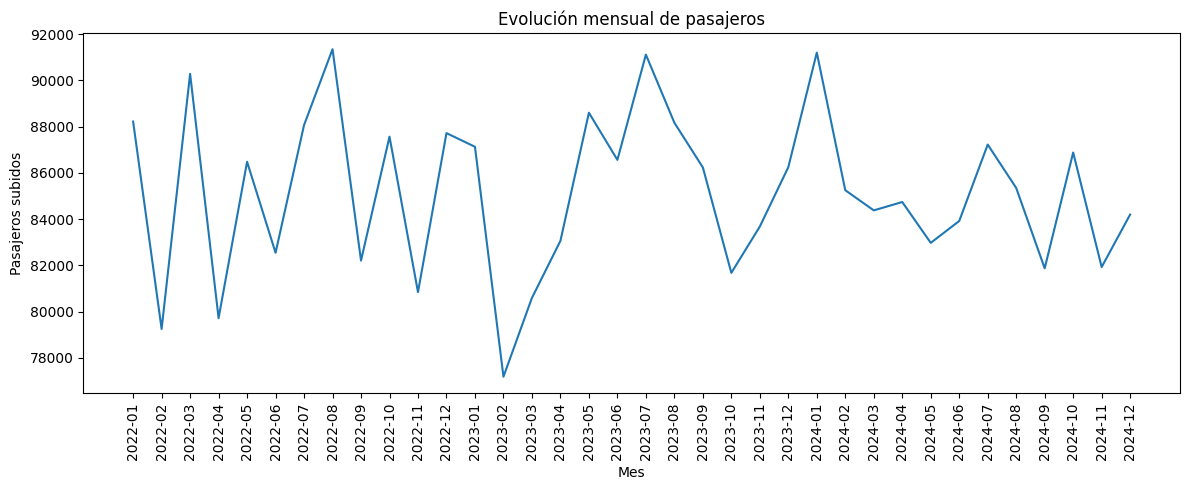

In [99]:
# Pregunta 1: ¿Cómo evoluciona el volumen de pasajeros a lo largo del tiempo?
viajes = dfs["fact_viajes"].copy()
viajes["fecha"] = pd.to_datetime(viajes["fecha"], errors="coerce")
mensual = viajes.groupby(viajes["fecha"].dt.to_period("M"))["pasajeros_subidos"].sum()
mensual.index = mensual.index.astype(str)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(mensual.index, mensual.values)
ax.set_title("Evolución mensual de pasajeros")
ax.set_xlabel("Mes")
ax.set_ylabel("Pasajeros subidos")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()


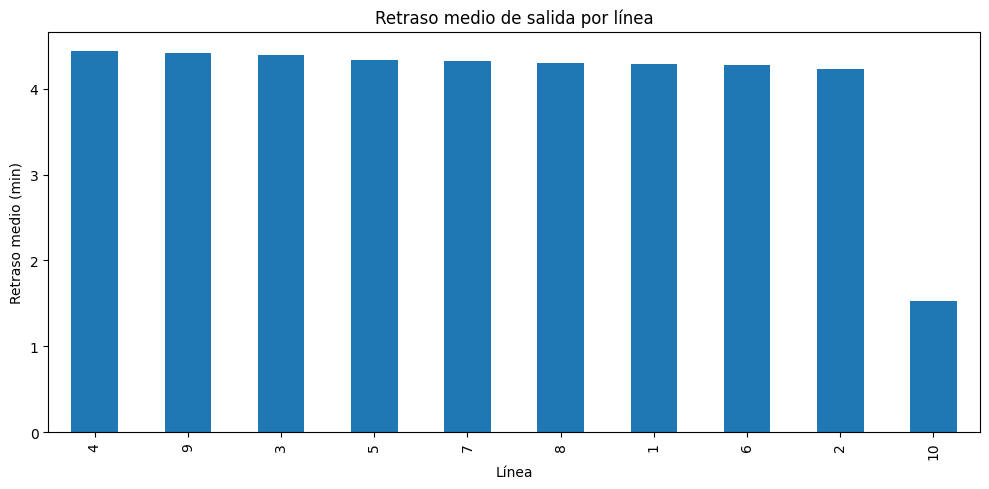

In [100]:
# Pregunta 2: ¿Qué líneas acumulan mayor retraso medio de salida?
retraso_linea = (
    dfs["fact_viajes"]
    .groupby("linea_id")["retraso_salida_min"]
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
retraso_linea.plot(kind="bar", ax=ax)
ax.set_title("Retraso medio de salida por línea")
ax.set_xlabel("Línea")
ax.set_ylabel("Retraso medio (min)")
plt.tight_layout()
plt.show()


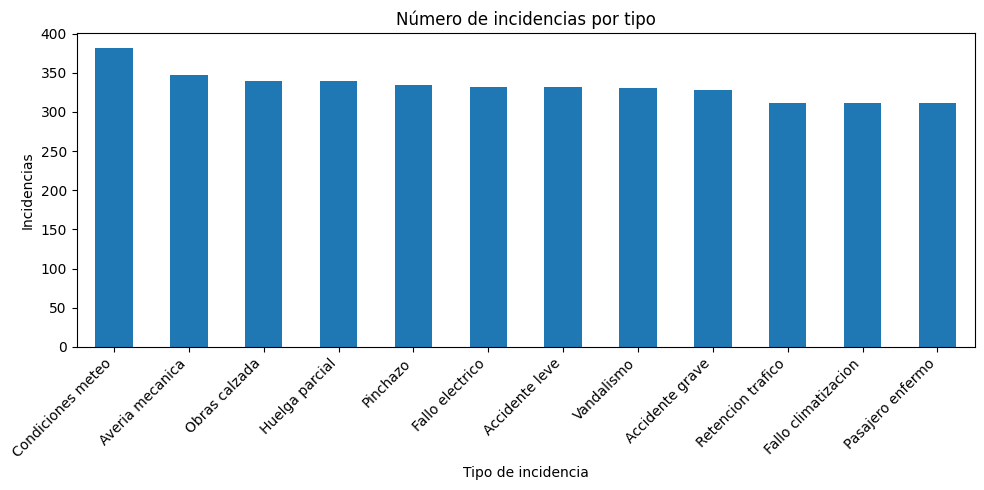

In [101]:
# Pregunta 3: ¿Qué tipos de incidencia aparecen con mayor frecuencia?
tipos = dfs["fact_incidencias"]["tipo_incidencia"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
tipos.plot(kind="bar", ax=ax)
ax.set_title("Número de incidencias por tipo")
ax.set_xlabel("Tipo de incidencia")
ax.set_ylabel("Incidencias")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


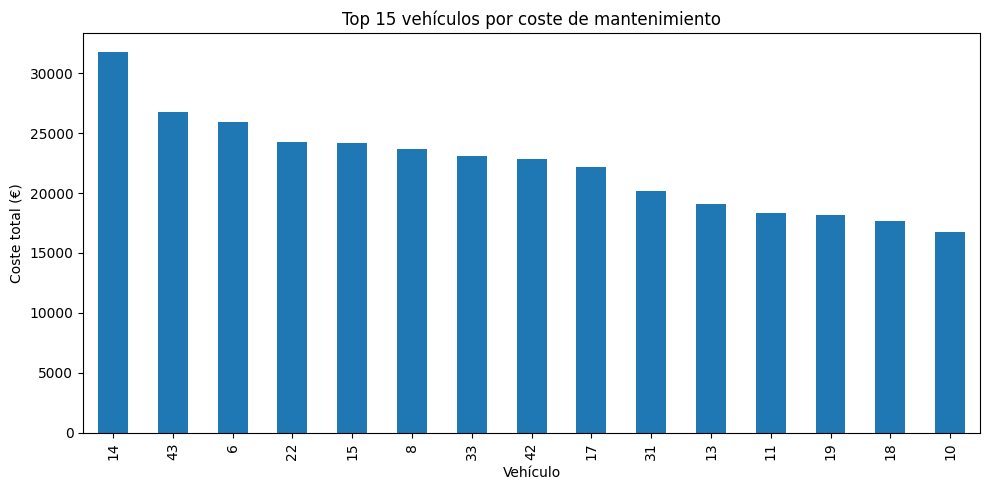

,coste_total,coste_medio_intervencion,intervenciones,vehiculos,coste_por_vehiculo
combustible,,,,,
Electrico,"188,157.240",804.091,234,12,"15,679.770"
Diesel,"422,989.340",810.324,522,27,"15,666.272"
Hibrido,"79,012.790",658.440,120,6,"13,168.798"


In [102]:
# Pregunta adicional: ¿Qué vehículos concentran más coste de mantenimiento?
# ¿Existe relación descriptiva con el tipo de combustible?

coste_vehiculo = (
    dfs["fact_mantenimiento"]
    .groupby("vehiculo_id")["coste_eur"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(10, 5))
coste_vehiculo.plot(kind="bar", ax=ax)
ax.set_title("Top 15 vehículos por coste de mantenimiento")
ax.set_xlabel("Vehículo")
ax.set_ylabel("Coste total (€)")
plt.tight_layout()
plt.show()

mantenimiento_vehiculo = dfs["fact_mantenimiento"].merge(
    dfs["dim_vehiculo"][["vehiculo_id", "combustible"]],
    on="vehiculo_id", how="left"
)

analisis_combustible = (
    mantenimiento_vehiculo
    .groupby("combustible")
    .agg(
        coste_total=("coste_eur", "sum"),
        coste_medio_intervencion=("coste_eur", "mean"),
        intervenciones=("coste_eur", "count"),
        vehiculos=("vehiculo_id", "nunique")
    )
)
analisis_combustible["coste_por_vehiculo"] = (
    analisis_combustible["coste_total"] / analisis_combustible["vehiculos"]
)
analisis_combustible = analisis_combustible.sort_values("coste_por_vehiculo", ascending=False)
display(analisis_combustible)


## Conclusiones del tratamiento de outliers

- En fact_viajes[consumo], el análisis global detectó numerosos valores atípicos, pero estos estaban asociados principalmente a vehículos eléctricos. Al analizar el consumo por tipo de combustible, el patrón dejó de considerarse anómalo, por lo que se conservaron.
- En fact_viajes[pasajeros_subidos] se detectaron valores de 183–184 pasajeros, pero los vehículos afectados tenían capacidad de hasta 185 pasajeros. Por tanto, eran valores extremos pero válidos.

- En fact_viajes[retraso_salida_min], pequeños valores negativos de -1, -2 y -3 minutos se conservaron porque representan salidas adelantadas plausibles. En cambio, el valor -99 se consideró erróneo y el retraso se recalculó a partir de las horas programada y real.

- En fact_mantenimiento[coste_eur], los costes elevados detectados mediante IQR se conservaron al comprobar que estaban relacionados principalmente con reparaciones de motor. Los costes negativos, en cambio, se trataron como errores de signo y se corrigieron.

- Los valores elevados de dias_fuera_servicio —entre 7 y 10 días en los casos detectados— se mantuvieron porque estaban asociados principalmente a mantenimientos correctivos y reparaciones de motor, siendo operativamente plausibles.

- En fact_incidencias, los valores elevados de duración de resolución se conservaron al aparecer en eventos como huelgas, fallos eléctricos, accidentes y averías mecánicas, donde una resolución prolongada resulta plausible.

- Los valores elevados de coste_estimado_eur de las incidencias también se conservaron, ya que estaban concentrados principalmente en categorías como seguridad y accidentes, sin evidencia suficiente para considerarlos errores.

# Conclusiones del análisis exploratorio

El análisis exploratorio ha permitido conocer la estructura de los 9 datasets de MetroBus e identificar los principales problemas de calidad antes de su carga en PostgreSQL y posterior análisis en Power BI.

## Calidad de los datos

Los valores nulos no están distribuidos de forma generalizada, sino concentrados en campos concretos. El caso más relevante aparece en `fact_viajes.consumo`, con 1.065 valores nulos (2,13 %), concentrados en vehículos eléctricos. También se detectaron 40 nulos en `pasajeros_subidos`, 15 en la categoría de mantenimiento y algunos casos aislados en las dimensiones de vehículos, conductores y paradas.

No todos los valores ausentes deben tratarse de la misma forma. Algunos pueden reconstruirse utilizando información existente en otras variables, mientras que aquellos para los que no existe evidencia suficiente deben mantenerse como desconocidos.

También se detectaron valores claramente inconsistentes, como un año de fabricación 2099, kilometraje negativo, coordenadas geográficas fuera de rango, un retraso de -99 minutos y costes de mantenimiento negativos. Estos casos requieren reglas de limpieza específicas antes de cargar los datos en el modelo definitivo.

## Valores extremos

El análisis mediante IQR permitió localizar distintos valores extremos. Sin embargo, un outlier estadístico no implica necesariamente un error de calidad.

Por ejemplo, se encontraron viajes con 183-184 pasajeros, pero son compatibles con vehículos cuya capacidad total alcanza los 185 pasajeros. También aparecen costes elevados de mantenimiento, tiempos largos de resolución de incidencias y varios días fuera de servicio que resultan coherentes con reparaciones de motor, accidentes u otras incidencias de mayor impacto.

Por este motivo, los valores extremos se conservan cuando existe una explicación operativa razonable y solo se corrigen cuando existe evidencia de que el dato es inválido.

## Integridad del modelo

La revisión de claves primarias y duplicados no mostró problemas: no se detectaron claves primarias nulas, claves primarias duplicadas ni filas completamente duplicadas.

También se comprobó la integridad referencial entre las tablas de hechos y dimensiones. Esta revisión fue especialmente importante en `dim_parada`, ya que eliminar una parada con coordenadas incompletas habría provocado referencias huérfanas en `fact_viajes`. Por ello se conserva la parada y se mantiene la coordenada desconocida como nula.

## Principales hallazgos de negocio

El dataset permite analizar de forma conjunta demanda, puntualidad, incidencias y mantenimiento.

Se observan diferencias en el retraso medio entre líneas, lo que permite identificar líneas con un comportamiento operativo diferente. Las incidencias tampoco se distribuyen de forma uniforme entre tipos, destacando especialmente las relacionadas con condiciones meteorológicas y averías mecánicas.

En mantenimiento existen diferencias importantes entre vehículos. Sin embargo, al comparar tecnologías de combustible es necesario considerar el tamaño de cada grupo: el mayor coste total de una tecnología no implica necesariamente un mayor coste por vehículo.

